# Segmentation-led model analysis contract

This notebook shows the tables and figures that the script emits in a Markdown report. Analytically defined synthetic tissue tests score sensitivity, reconstruction failures and numerical stability before real model comparisons.

## Introduction

### Assumptions

No models were trained. The spectral extension runs evaluation-only inference through six existing checkpoints from the script; the notebook only displays saved results. The new spectral comparison uses three independent input seeds, one fixed clustering seed, and three existing trained checkpoints per family. Archived verifier controls used three clustering seeds. Clustering parameters are fixed in the settings. Production analyses must use the preserved kidney split and frozen validation-derived thresholds/prevalence.

### Notation

Z is the encoder latent matrix N×D. Y is the reference tissue partition; C is an unsupervised cluster assignment. X and X_hat are target and reconstructed spectra N×M. Q denotes normalized covariance eigenvalues.

In [1]:
from pathlib import Path
from IPython.display import Image, Markdown, display
from msi_autoencoder_wrapper.analysis.autoencoder.experiments.reference_validation_precompute import load_settings, load_table, run_command

SETTINGS_PATH = Path("analysis_settings.yaml")
if not SETTINGS_PATH.is_file():
    SETTINGS_PATH = Path("assets/experiments/autoencoder_architecture/notebooks/agent_analysis_validation/analysis_settings.yaml")
settings = load_settings(SETTINGS_PATH)
results = Path(settings["output"])
print(run_command(SETTINGS_PATH, "datasets"))
print(run_command(SETTINGS_PATH, "spectral_partitions"))

2026-10-13 22:16:13,578 | INFO     | msi_autoencoder_wrapper.utils.module_search:79 | Discovered 1 implementation module(s) in package 'msi_autoencoder_wrapper.binners.binners_strategies'.


2026-10-13 22:16:13,581 | INFO     | msi_autoencoder_wrapper.utils.module_search:79 | Discovered 6 implementation module(s) in package 'msi_autoencoder_wrapper.binners.inverse_strategies'.


/home/max/repositories/MSIAutoEncoderWrapper/.venv/bin/python -m msi_autoencoder_wrapper.analysis.autoencoder.experiments.reference_validation_precompute --settings /home/max/repositories/MSIAutoEncoderWrapper/assets/experiments/autoencoder_architecture/notebooks/agent_analysis_validation/analysis_settings.yaml --analysis datasets
/home/max/repositories/MSIAutoEncoderWrapper/.venv/bin/python -m msi_autoencoder_wrapper.analysis.autoencoder.experiments.reference_validation_precompute --settings /home/max/repositories/MSIAutoEncoderWrapper/assets/experiments/autoencoder_architecture/notebooks/agent_analysis_validation/analysis_settings.yaml --analysis spectral_partitions


## Raw spectra and trained representations on spatial references

### Methodology

#### Theoretical

A tissue fixture assigns a spectral mixture prototype to each region. All prototypes contain the same eight Gaussian peak components, with cyclically permuted relative amplitudes. Independent lognormal component variation produces noise while TIC remains one. Region geometry is not an encoder or clustering feature. CUDA K-means, DBSCAN and diagonal-covariance GMM receive the same rows, first as raw TIC spectra and then as actual trained encoder outputs.

#### Implementation

The script uses the saved 200–900 m/z / 0.55 axis, six fixed checkpoints (three clean B0 repetitions and three pretraining/unfrozen-head repetitions), three input seeds and one fixed clustering seed. Reference counts are 2 or 5 and are prespecified for K-means/GMM; DBSCAN infers its count and noise. Its radius is the fixed 0.95 quantile of 12-neighbour distances including self; no reference labels are used to select the radius. GMM uses diagonal covariance in both spaces. Two input log-amplitude standard deviations, 0.05 and 0.8, test different overlap levels. Gaussian mixtures are diagnostic fixtures, not regenerated pretraining data or biological truth.

Spectral mixture arithmetic, model inference, clustering and latent covariance rank run on CUDA float32. There is no CPU model comparison or clustering fallback. Repeatability is checked on GPU at the original atol=1e-5/rtol=1e-4. Checkpoint bytes and all model parameters/buffers are checked for preservation. Host utilities decode/write files, score exported integer assignments and render figures. Parameters are not trained or tuned on these fixtures. Earlier CPU-clustering/float64-inference results are retained in archive/spectral_cpu_float64 and excluded from current tables.

#### Figure descriptions

Each comparison JPEG contains the same reference plus CUDA K-means, GMM-diagonal and DBSCAN predictions. Shared region colours use score-only matching. Method titles show assignment accuracy, macro Dice and noise. Error JPEGs show yellow incorrect pixels. Spectral panels show class-wise mean inputs and 10–90% variation; trained-model panels additionally show mean decoder output as a dashed line. The central ring region is smaller, testing minority-region recovery.

### Remarks

Historical checkpoint families differ in data, objectives and budgets; this is a representation probe, not a controlled pretraining-effect estimate. Good synthetic scores do not establish biological segmentation quality. Displayed seed/repetition are fixed before scoring; every evaluated repetition remains in numerical tables.

### Notes

In [2]:
print(run_command(SETTINGS_PATH, "spectral_partitions"))
comparison = load_table(settings, "spectral_partition_summary.csv")
gallery = load_table(settings, "spectral_partition_gallery.csv")
display(comparison)
display(load_table(settings, "spectral_model_numerical_checks.csv"))

/home/max/repositories/MSIAutoEncoderWrapper/.venv/bin/python -m msi_autoencoder_wrapper.analysis.autoencoder.experiments.reference_validation_precompute --settings /home/max/repositories/MSIAutoEncoderWrapper/assets/experiments/autoencoder_architecture/notebooks/agent_analysis_validation/analysis_settings.yaml --analysis spectral_partitions


,layout,amplitude_noise,family,clustering_method,matched_accuracy_mean,matched_accuracy_std,macro_dice_mean,macro_dice_std,boundary_f1_mean,boundary_f1_std,noise_fraction_mean,noise_fraction_std
0,concentric_rings,0.05,clean_b0,dbscan,0.967250,0.010113,0.844379,0.069197,0.998041,0.002938,0.032750,0.010113
1,concentric_rings,0.05,clean_b0,gmm_diag,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000
2,concentric_rings,0.05,clean_b0,kmeans,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000
3,concentric_rings,0.05,pretraining_unfrozen,dbscan,0.974451,0.015279,0.874803,0.090595,0.997353,0.002653,0.025549,0.015279
4,concentric_rings,0.05,pretraining_unfrozen,gmm_diag,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000
5,concentric_rings,0.05,pretraining_unfrozen,kmeans,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000
6,concentric_rings,0.05,raw_tic_spectra,dbscan,0.992798,0.002357,0.988981,0.009419,0.997547,0.002249,0.007202,0.002357
7,concentric_rings,0.05,raw_tic_spectra,gmm_diag,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000
8,concentric_rings,0.05,raw_tic_spectra,kmeans,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000
9,concentric_rings,0.80,clean_b0,dbscan,0.352366,0.011471,0.152035,0.072870,0.202546,0.055869,0.012860,0.005346


,family,repetition,check,device,compute_dtype,max_absolute_error,atol,rtol,passed
0,clean_b0,0,gpu_repeat_latent,cuda,float32,0.000000e+00,0.00001,0.0001,True
1,clean_b0,0,gpu_repeat_reconstruction,cuda,float32,1.862645e-09,0.00001,0.0001,True
2,clean_b0,1,gpu_repeat_latent,cuda,float32,0.000000e+00,0.00001,0.0001,True
3,clean_b0,1,gpu_repeat_reconstruction,cuda,float32,1.862645e-09,0.00001,0.0001,True
4,clean_b0,2,gpu_repeat_latent,cuda,float32,0.000000e+00,0.00001,0.0001,True
5,clean_b0,2,gpu_repeat_reconstruction,cuda,float32,9.313226e-10,0.00001,0.0001,True
6,pretraining_unfrozen,0,gpu_repeat_latent,cuda,float32,0.000000e+00,0.00001,0.0001,True
7,pretraining_unfrozen,0,gpu_repeat_reconstruction,cuda,float32,1.862645e-09,0.00001,0.0001,True
8,pretraining_unfrozen,1,gpu_repeat_latent,cuda,float32,0.000000e+00,0.00001,0.0001,True
9,pretraining_unfrozen,1,gpu_repeat_reconstruction,cuda,float32,3.725290e-09,0.00001,0.0001,True


## Two spectral regions

### Methodology

#### Theoretical

The two_stripes reference fixes region identity independently of the model representation. The ring exterior is unknown; region scores use only observed source pixels.

#### Implementation

The following cells read already-generated method, error and spectral-profile JPEGs. Noise level and selected representations are presentation controls; numerical results for every seed/model repetition remain available in the CSV. No inference or clustering executes here.

#### Figure descriptions

The first panel is the reference. The following panels compare all three clustering methods on the identical observation. A second figure shows assignment errors; spectral profiles reveal whether apparent tissue classes correspond to distinct spectra and what the decoder preserves.

### Remarks

Changing the displayed representation does not change the fixed scoring protocol.

### Notes

### raw_tic_spectra; amplitude noise=0.8

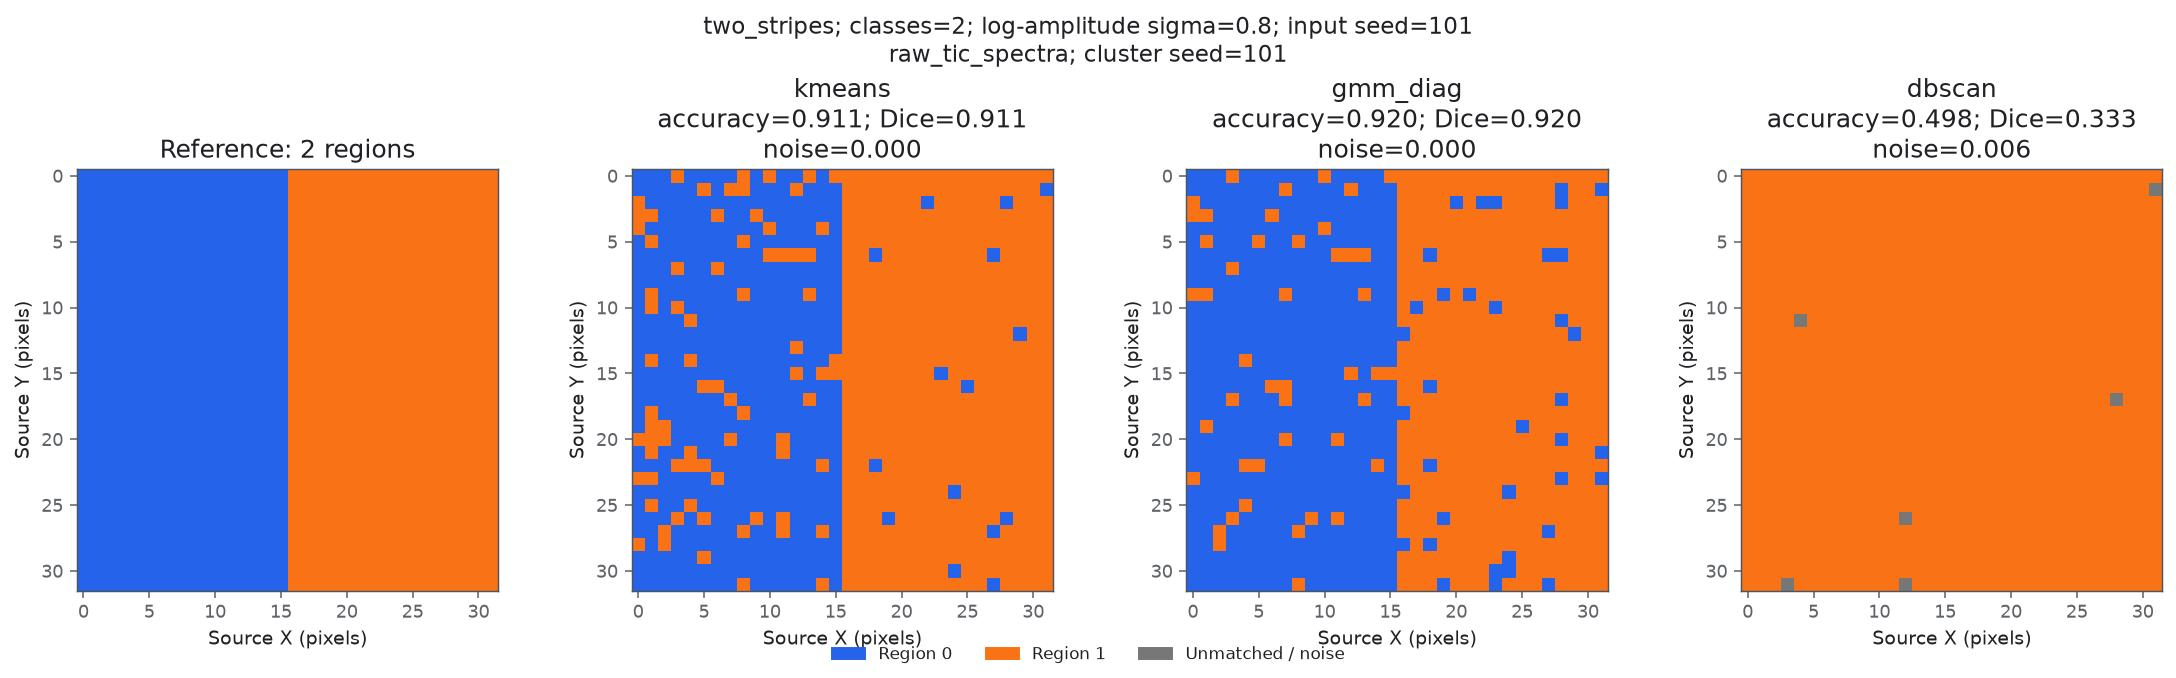

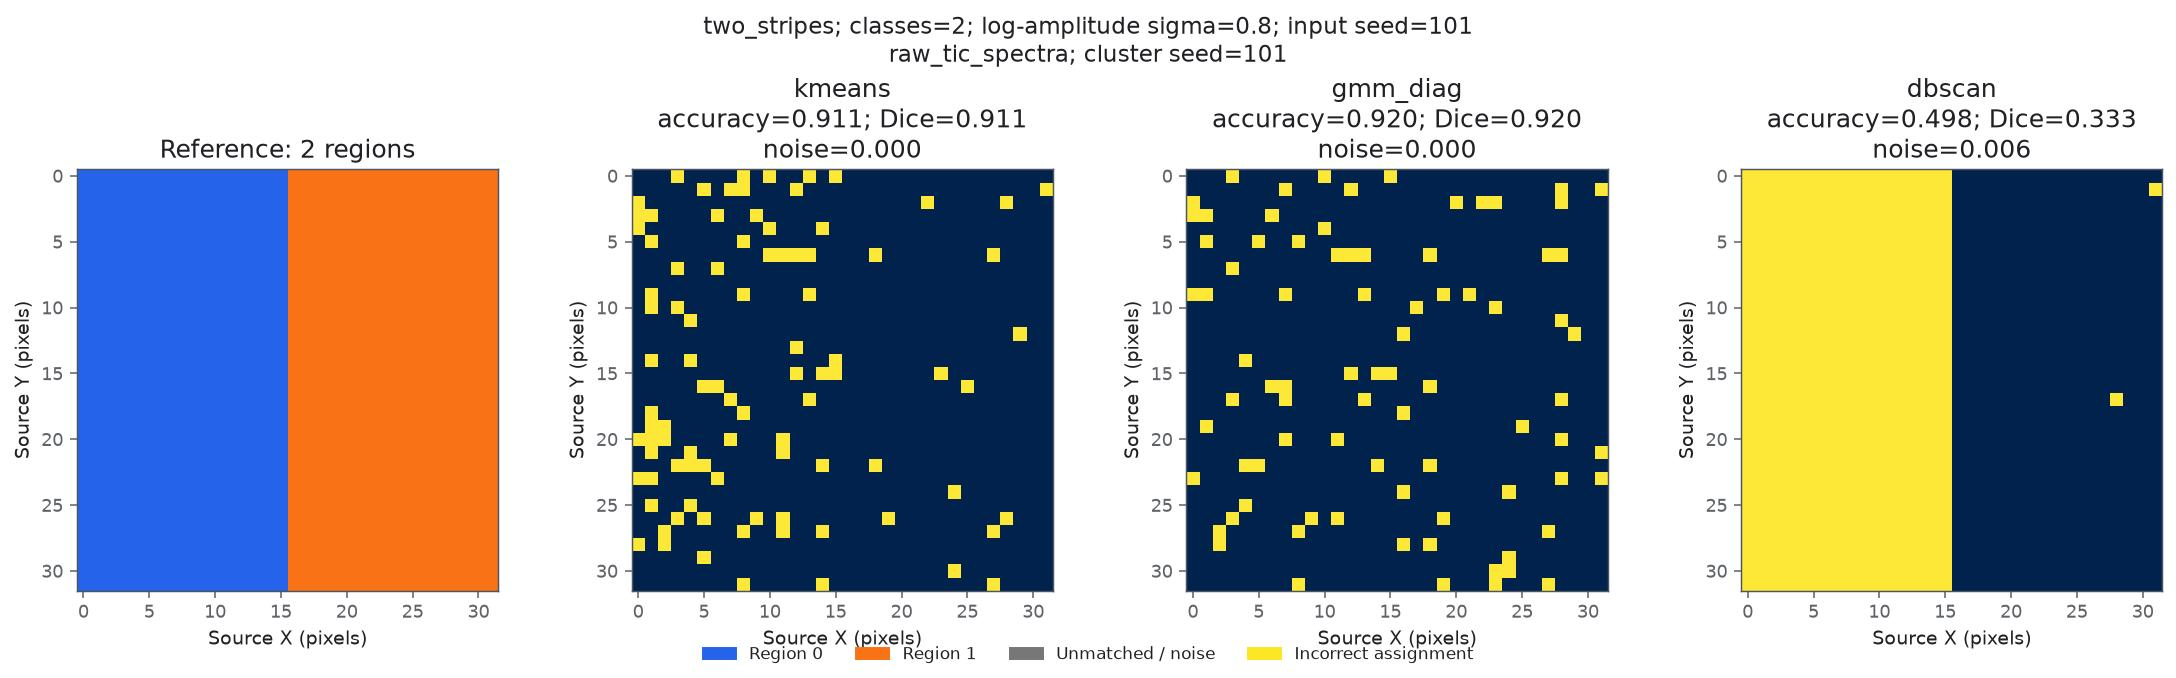

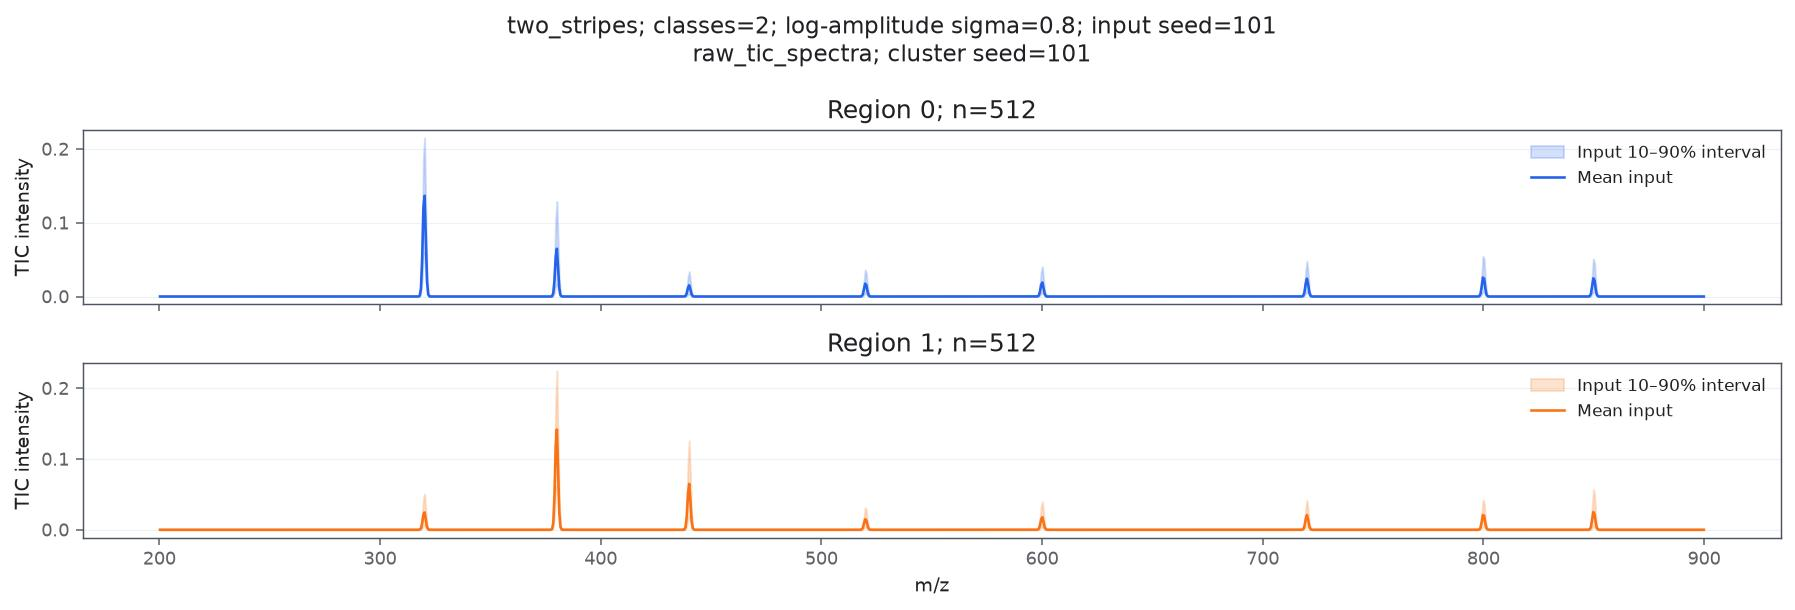

### clean_b0_rep_00; amplitude noise=0.8

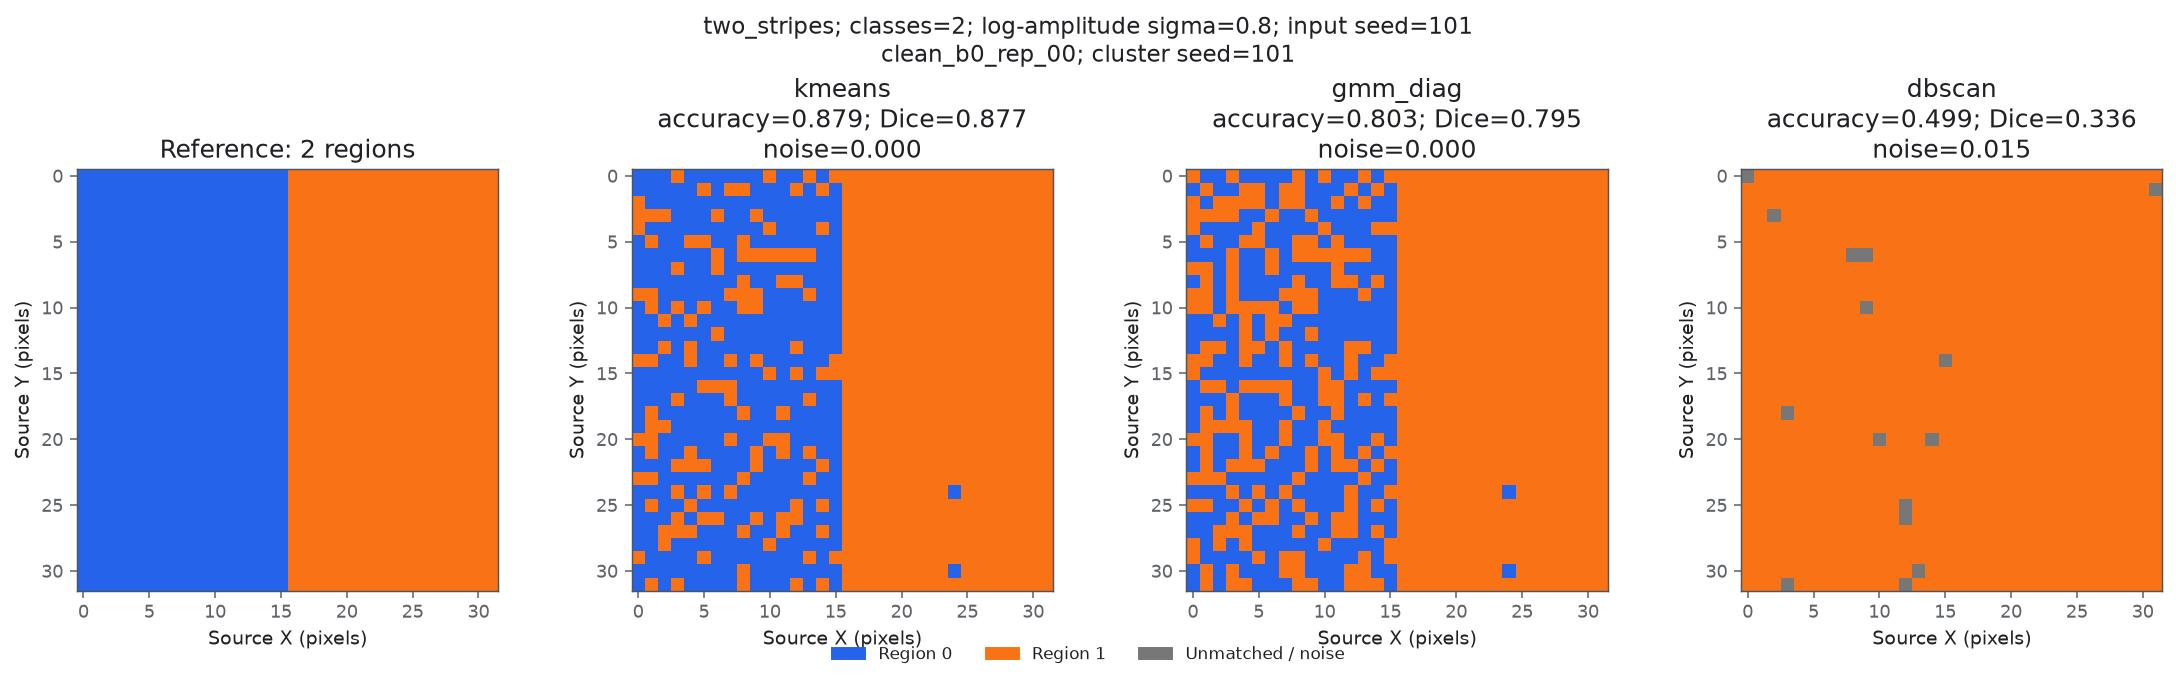

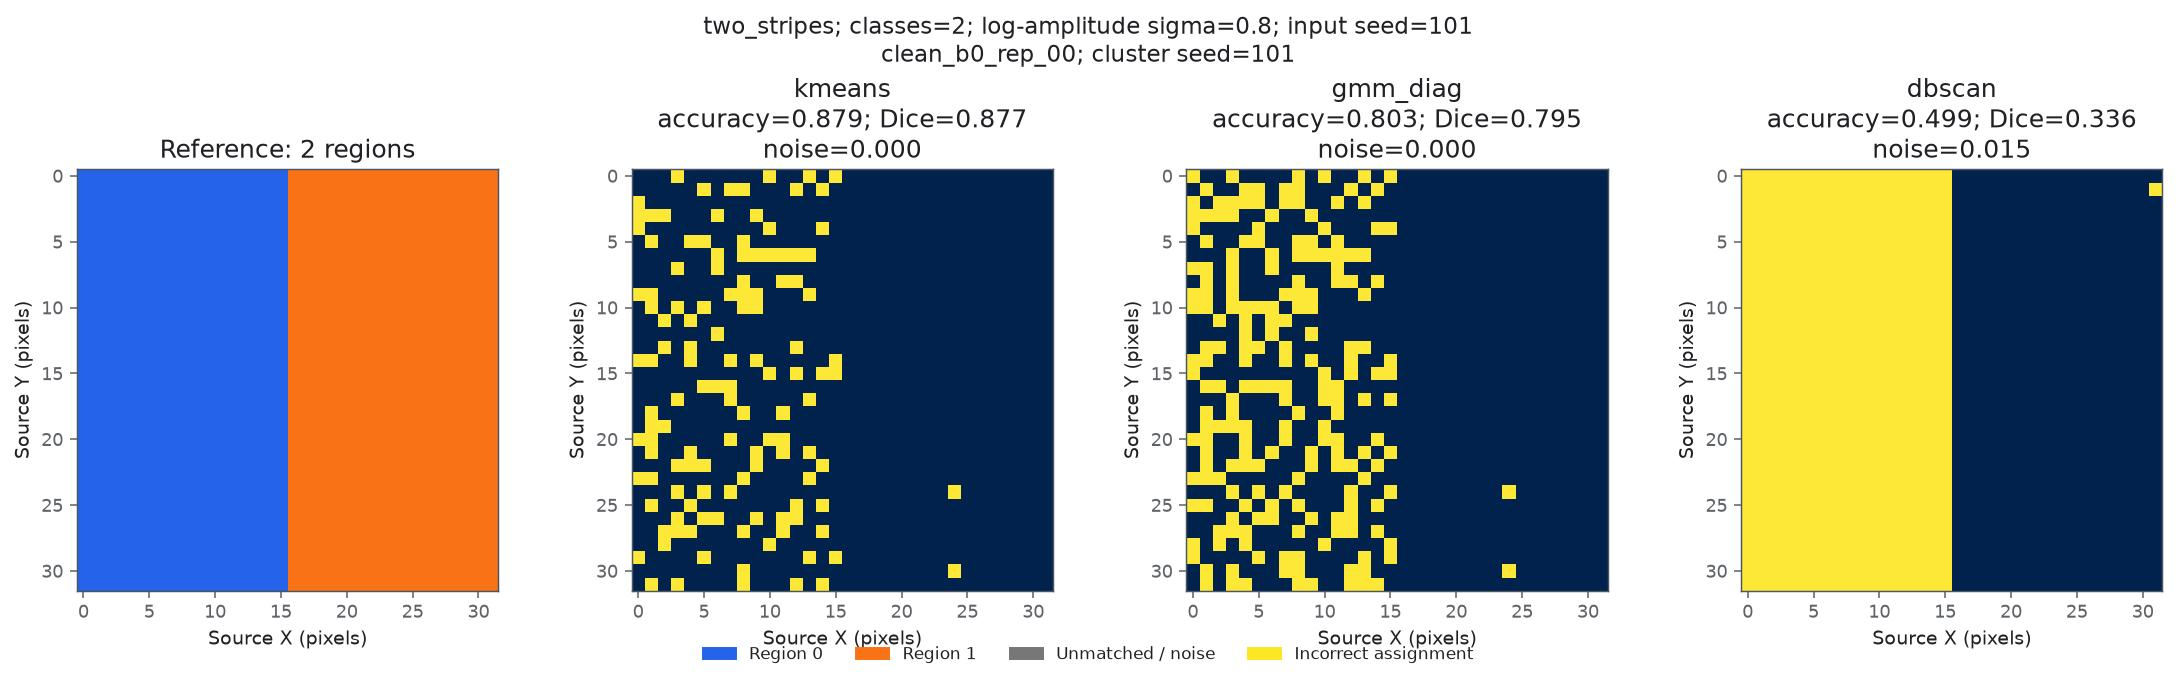

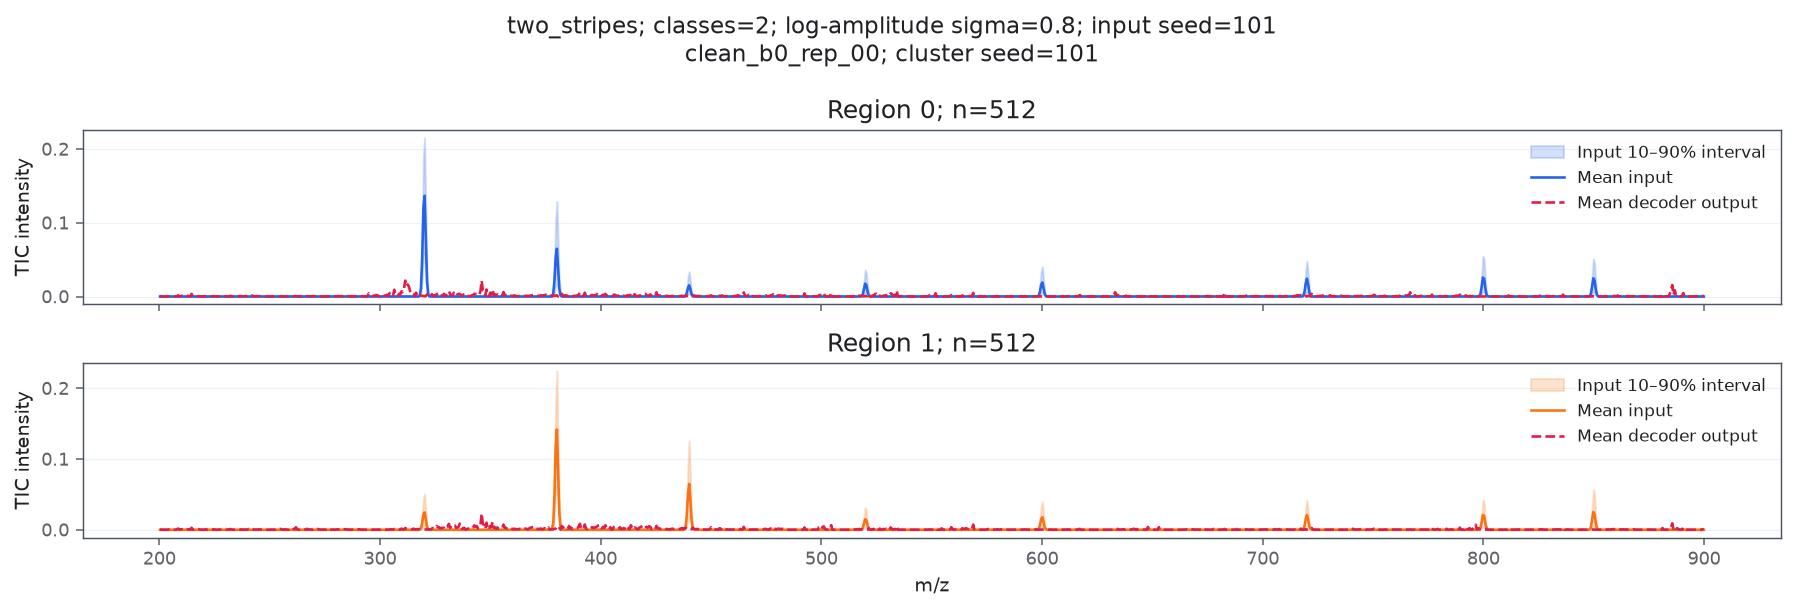

### pretraining_unfrozen_rep_00; amplitude noise=0.8

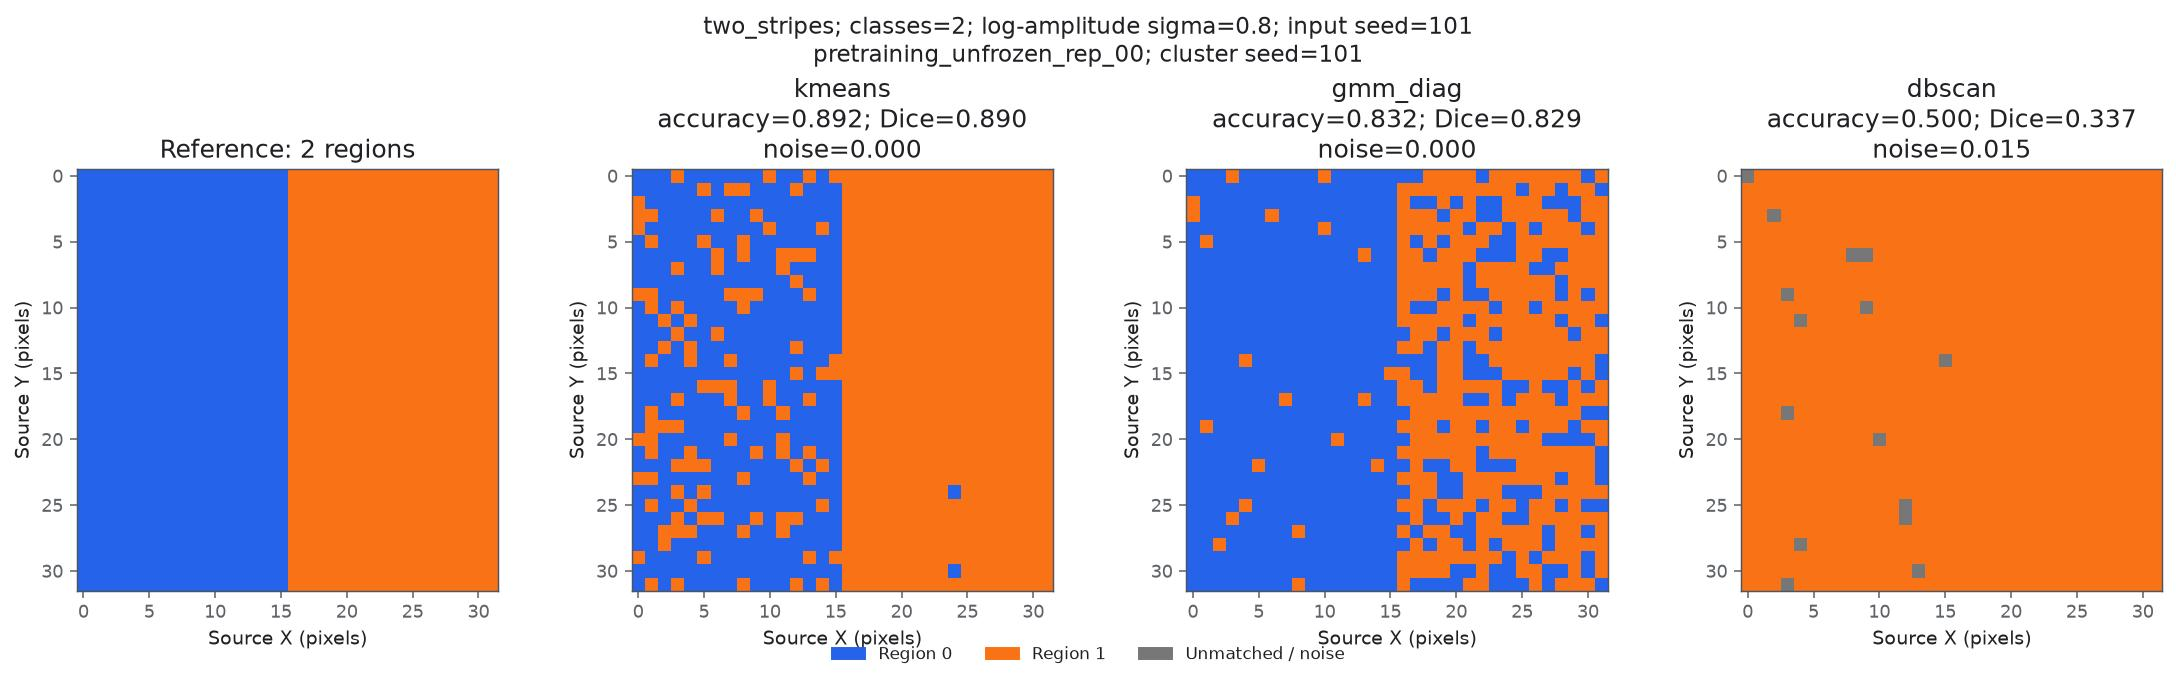

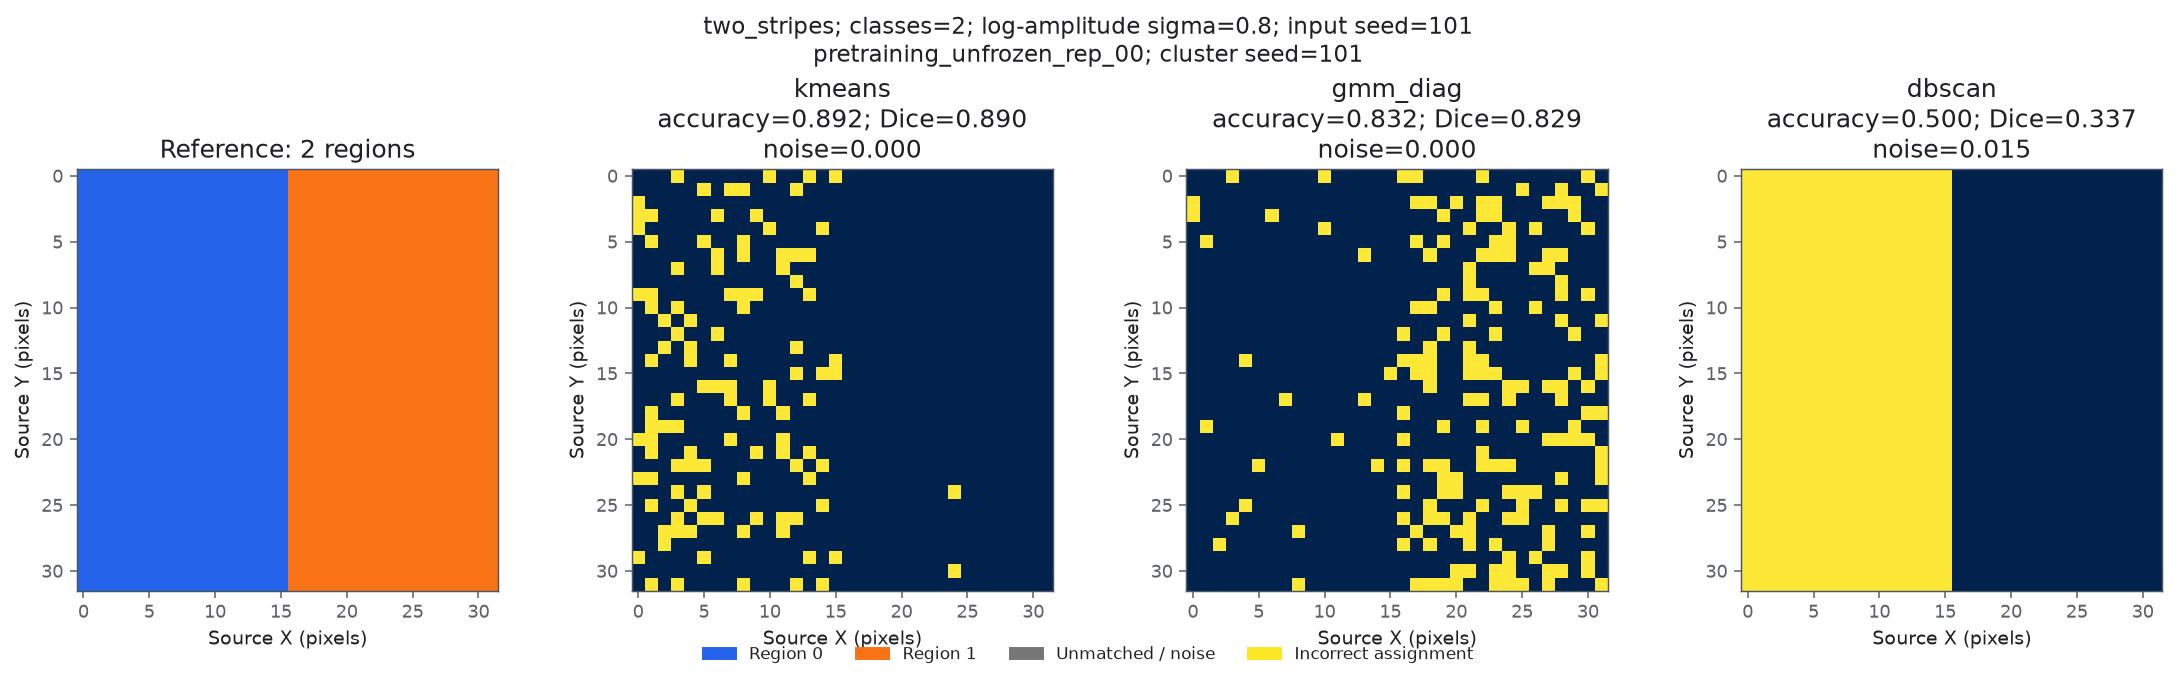

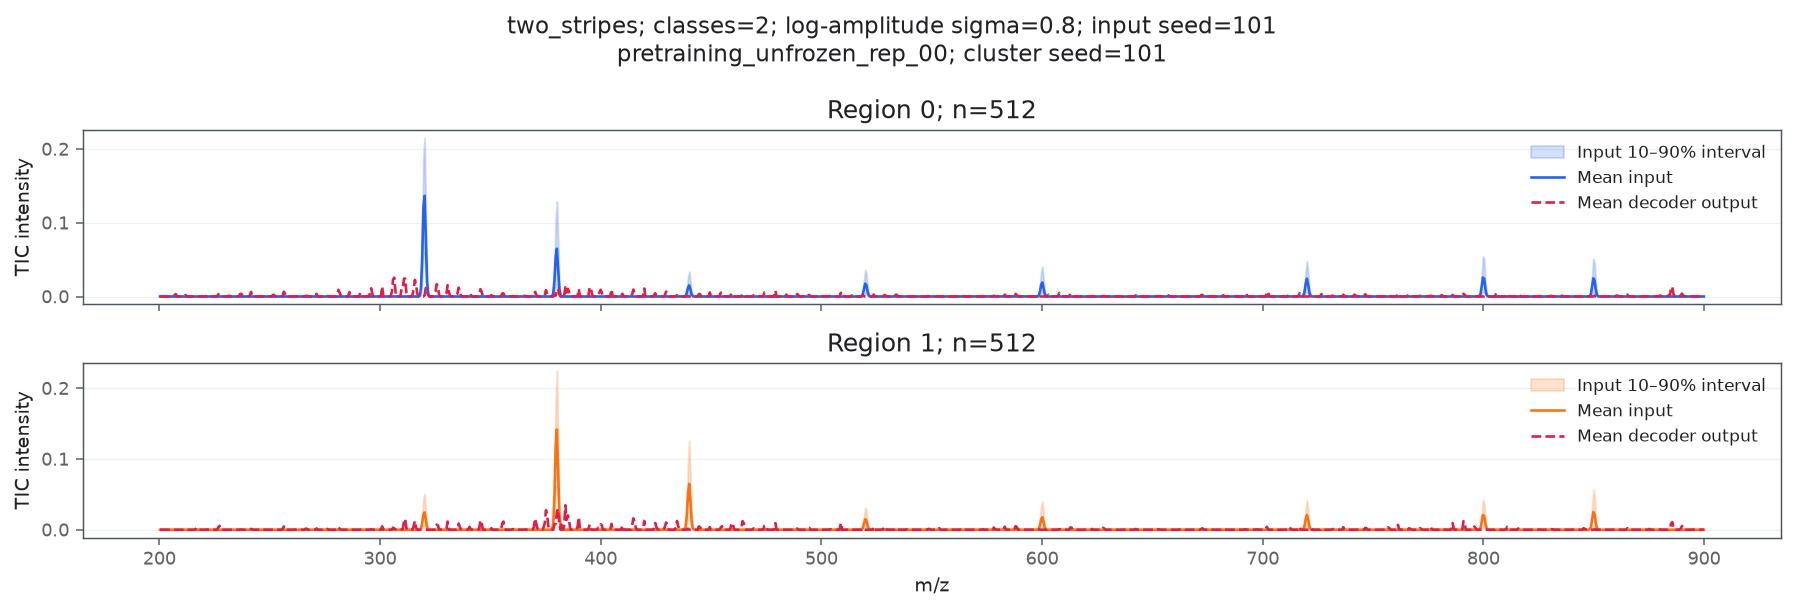

In [3]:
LAYOUT = "two_stripes"
NOISE = settings["spectral_partition_comparison"]["relative_amplitude_noise"][-1]
REPRESENTATIONS = ["raw_tic_spectra", "clean_b0_rep_00", "pretraining_unfrozen_rep_00"]
SHOW_ERRORS = True
SHOW_SPECTRA = True
selected = gallery[(gallery.layout == LAYOUT) & (gallery.noise == NOISE) & gallery.representation.isin(REPRESENTATIONS)]
for row in selected.itertuples():
    display(Markdown(f"### {row.representation}; amplitude noise={row.noise}"))
    display(Image(filename=str(results / "plots" / f"{row.plot_stem}.jpeg")))
    if SHOW_ERRORS:
        display(Image(filename=str(results / "plots" / f"{row.plot_stem}_errors.jpeg")))
    if SHOW_SPECTRA:
        display(Image(filename=str(results / "plots" / f"{row.plot_stem}_spectra.jpeg")))

## Five parallel spectral regions

### Methodology

#### Theoretical

The many_stripes reference fixes region identity independently of the model representation. The ring exterior is unknown; region scores use only observed source pixels.

#### Implementation

The following cells read already-generated method, error and spectral-profile JPEGs. Noise level and selected representations are presentation controls; numerical results for every seed/model repetition remain available in the CSV. No inference or clustering executes here.

#### Figure descriptions

The first panel is the reference. The following panels compare all three clustering methods on the identical observation. A second figure shows assignment errors; spectral profiles reveal whether apparent tissue classes correspond to distinct spectra and what the decoder preserves.

### Remarks

Changing the displayed representation does not change the fixed scoring protocol.

### Notes

### raw_tic_spectra; amplitude noise=0.8

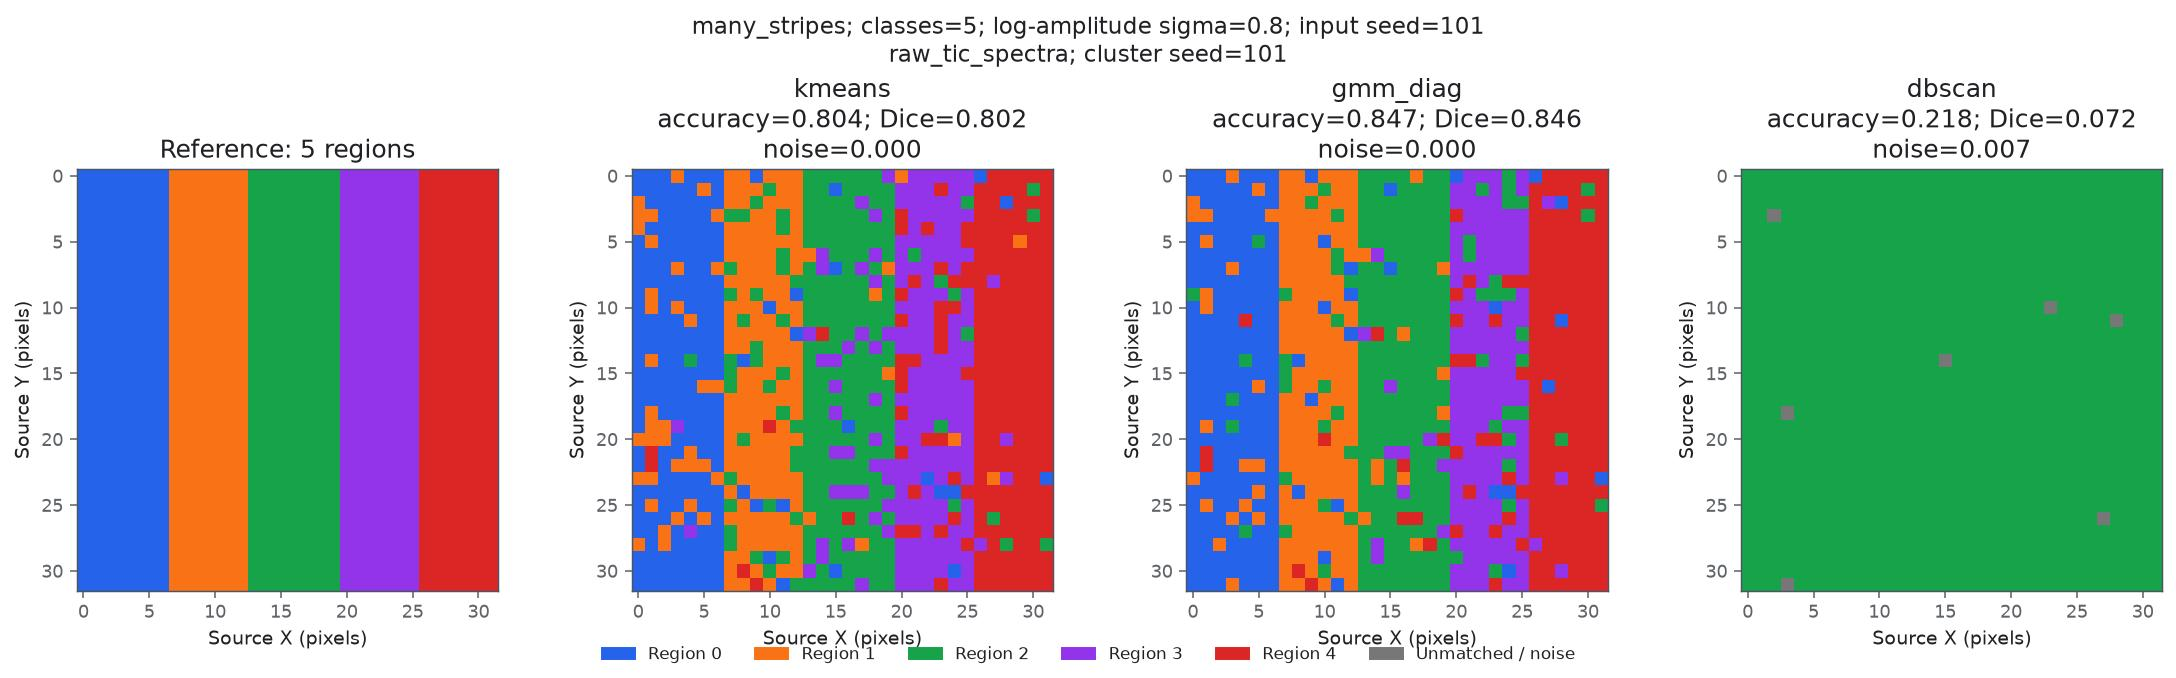

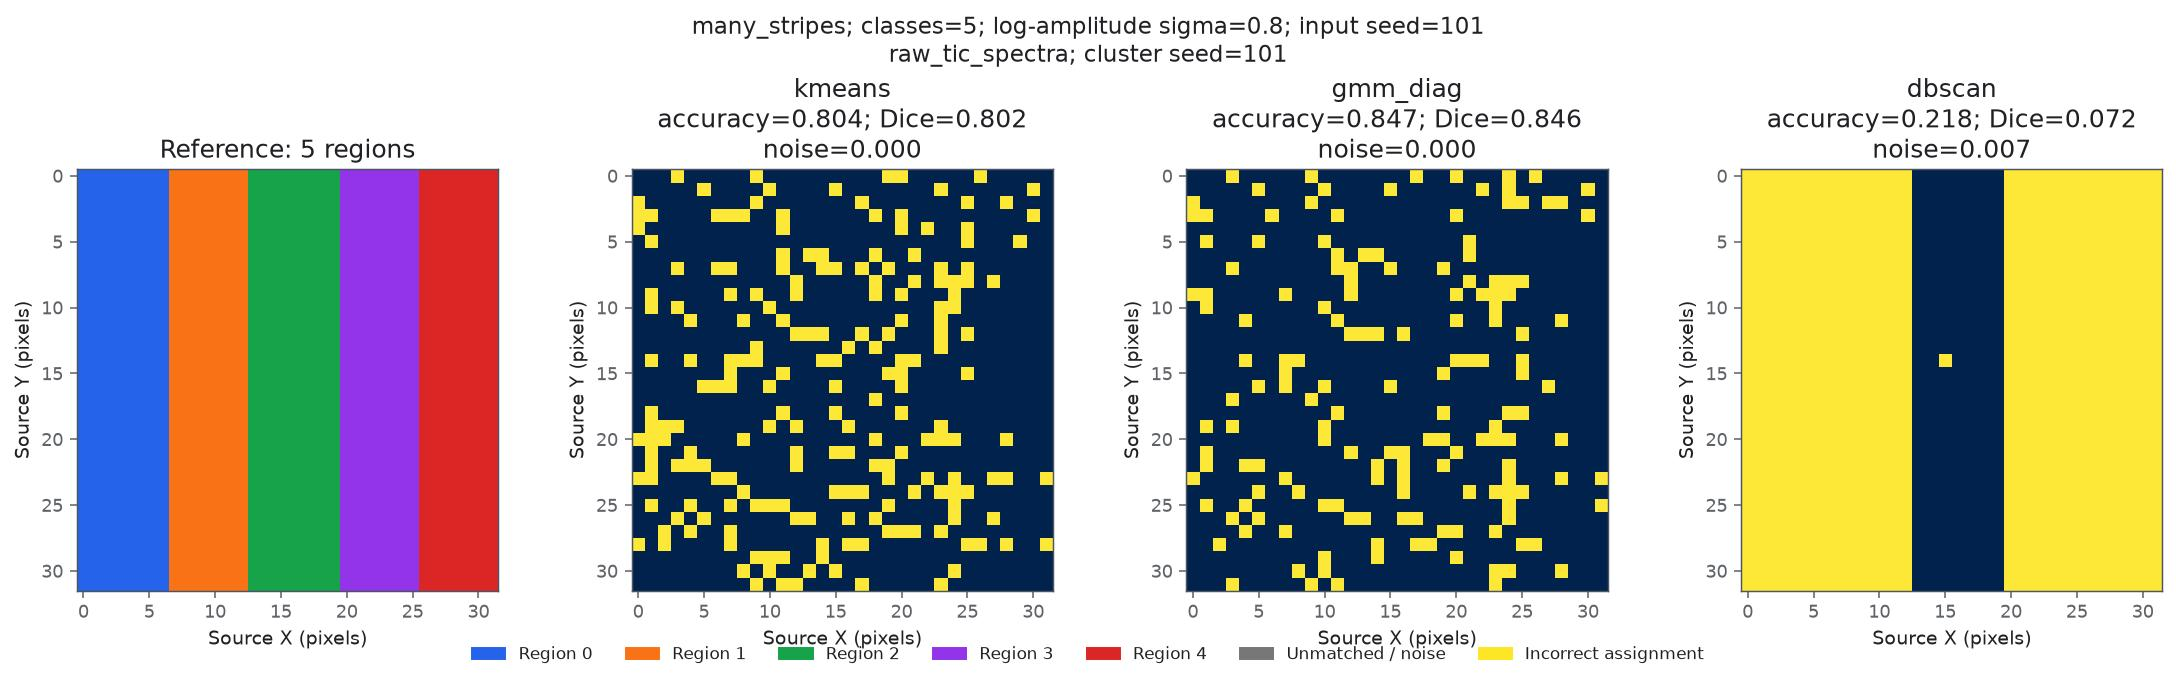

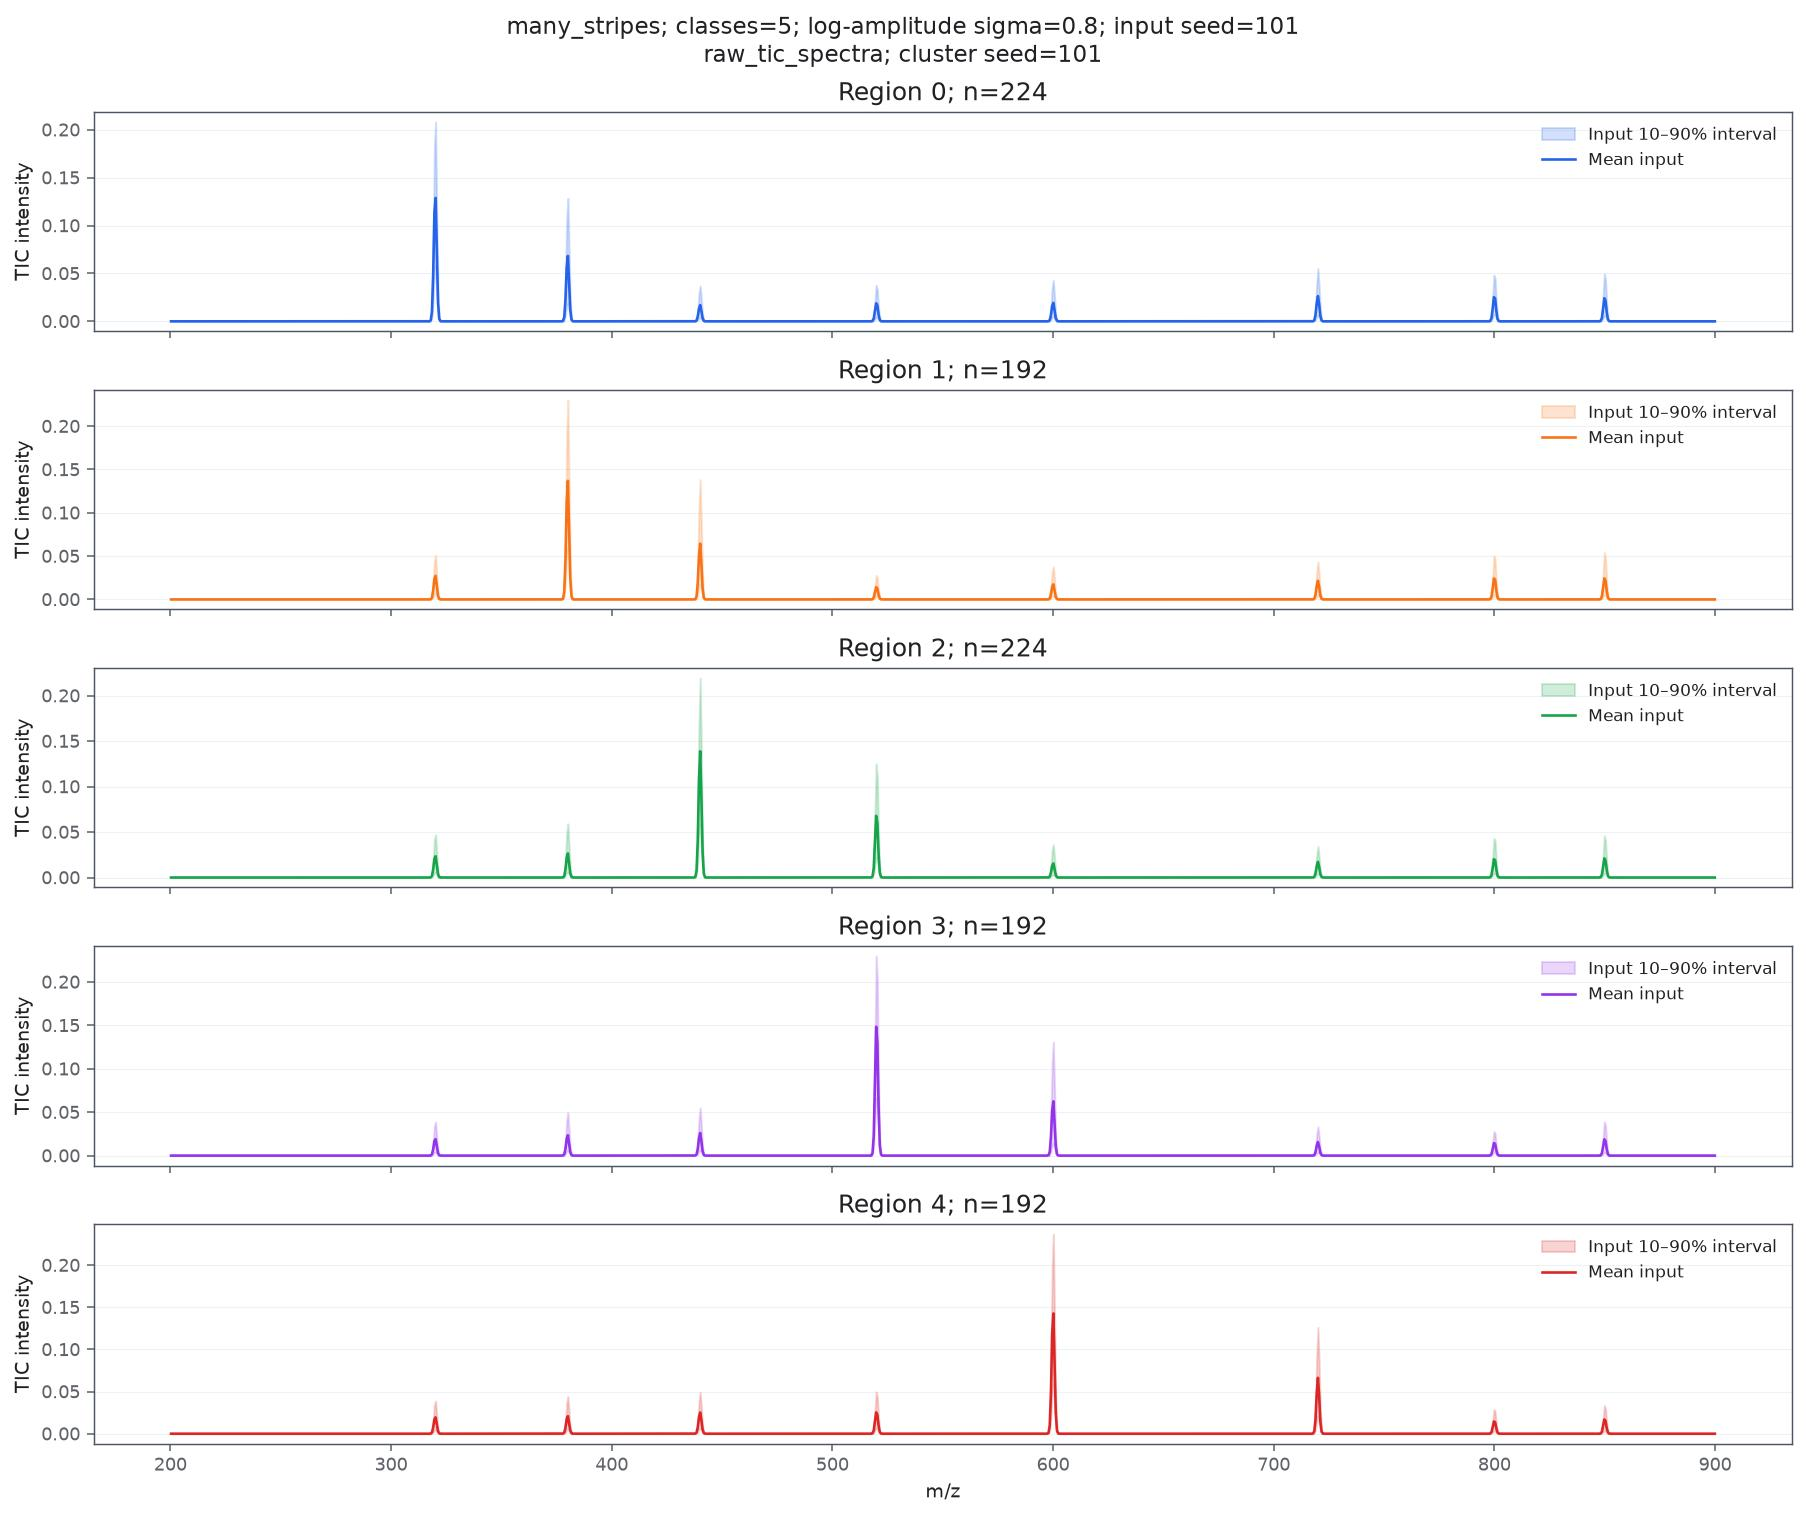

### clean_b0_rep_00; amplitude noise=0.8

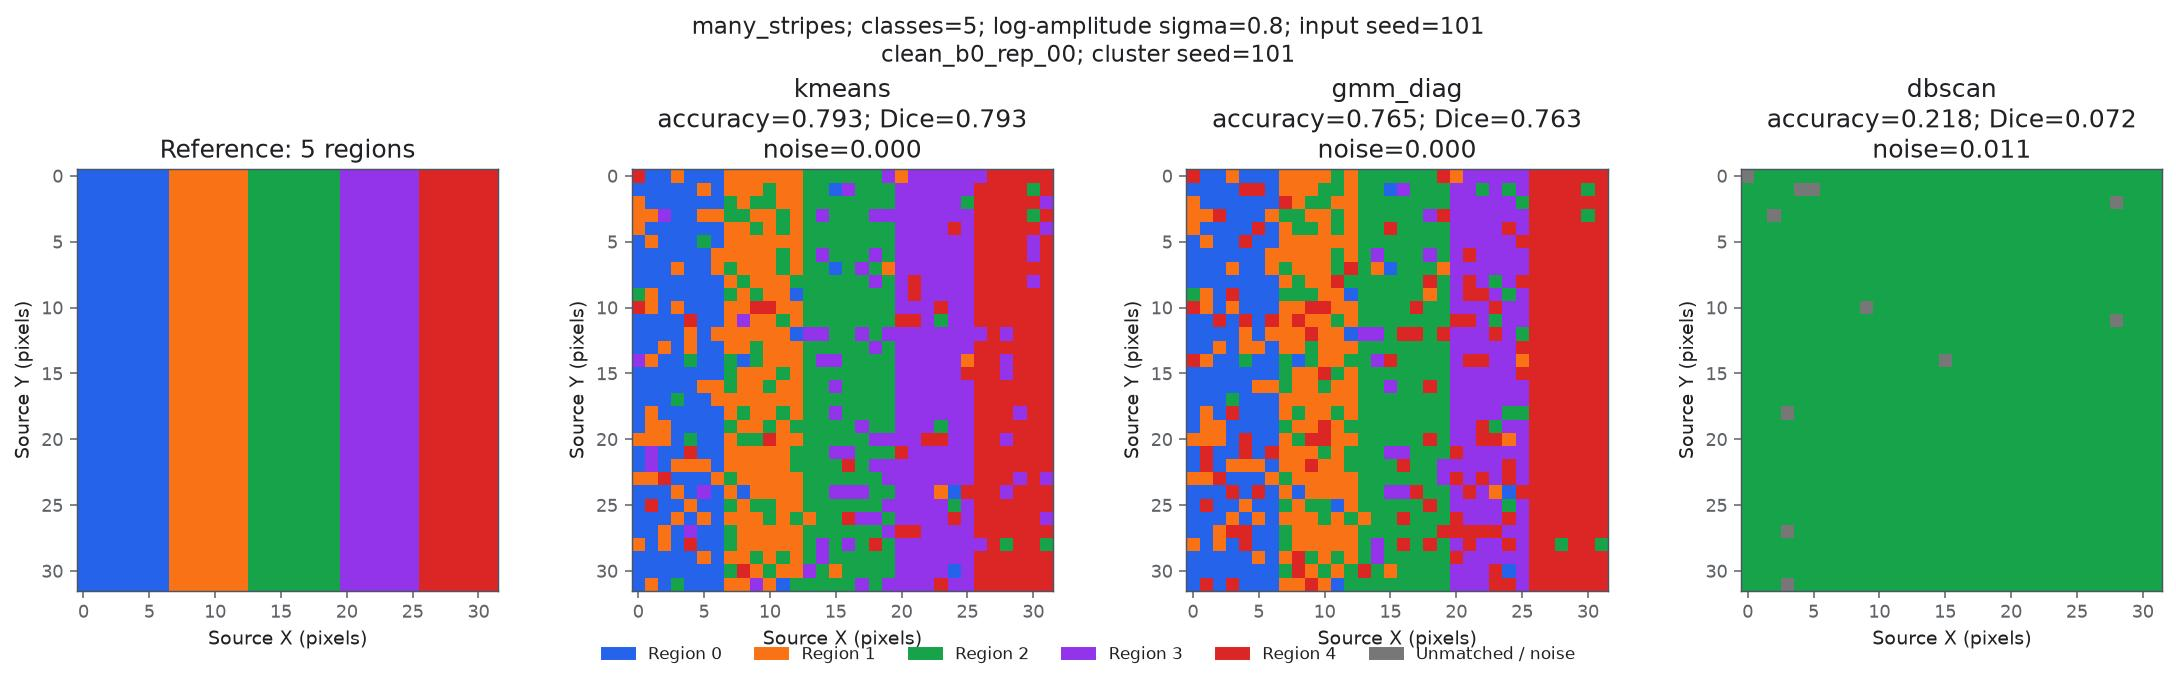

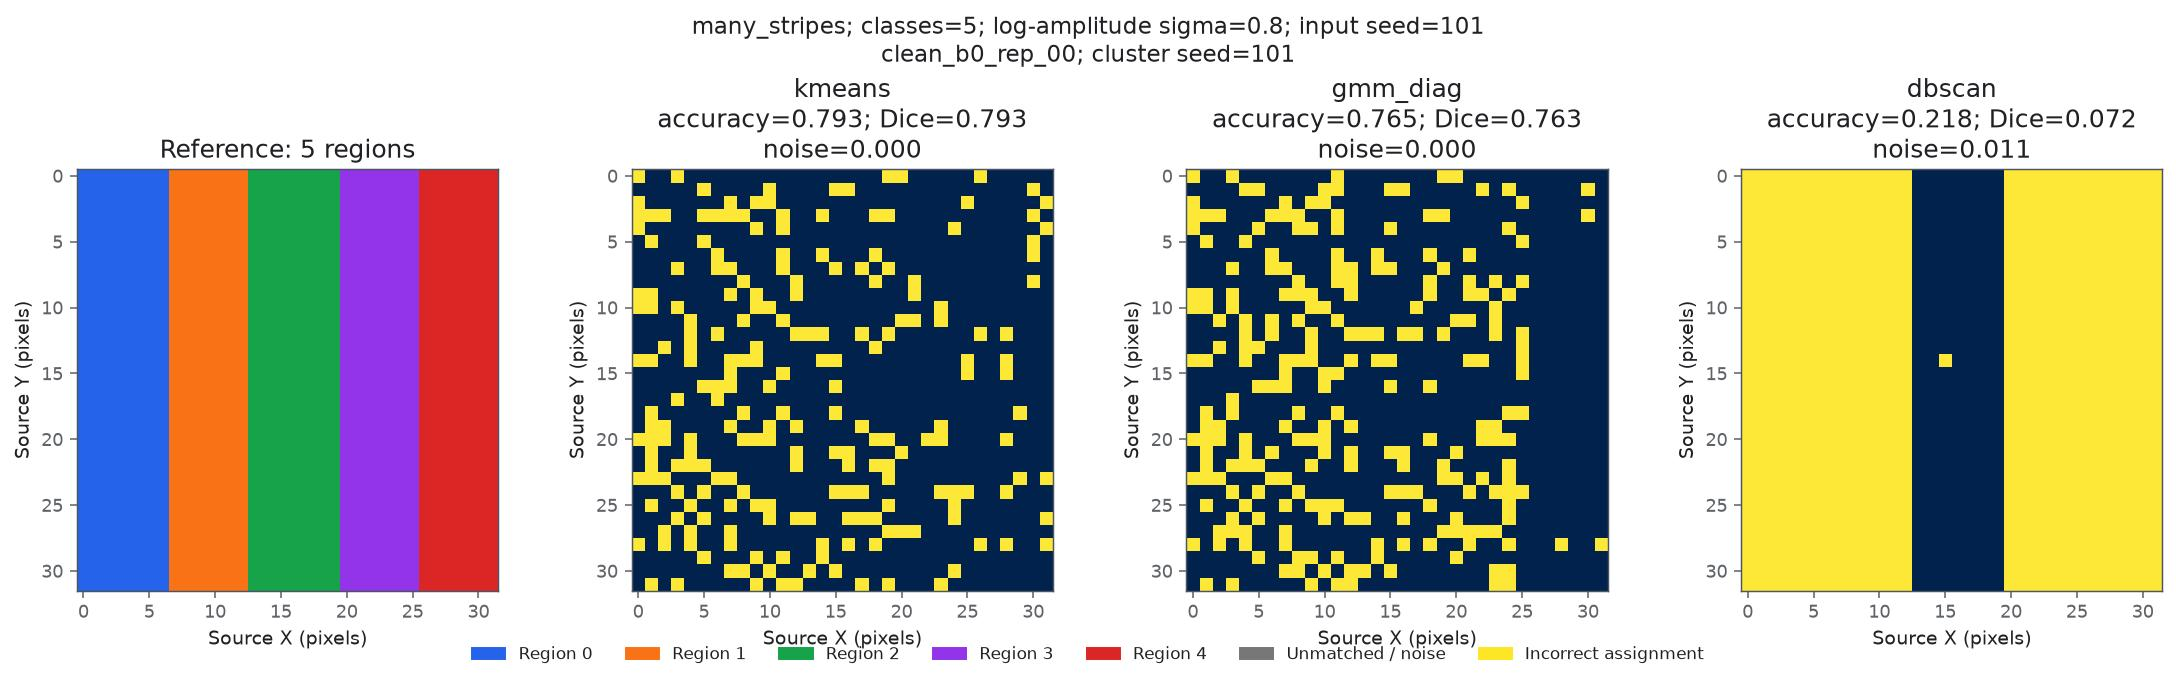

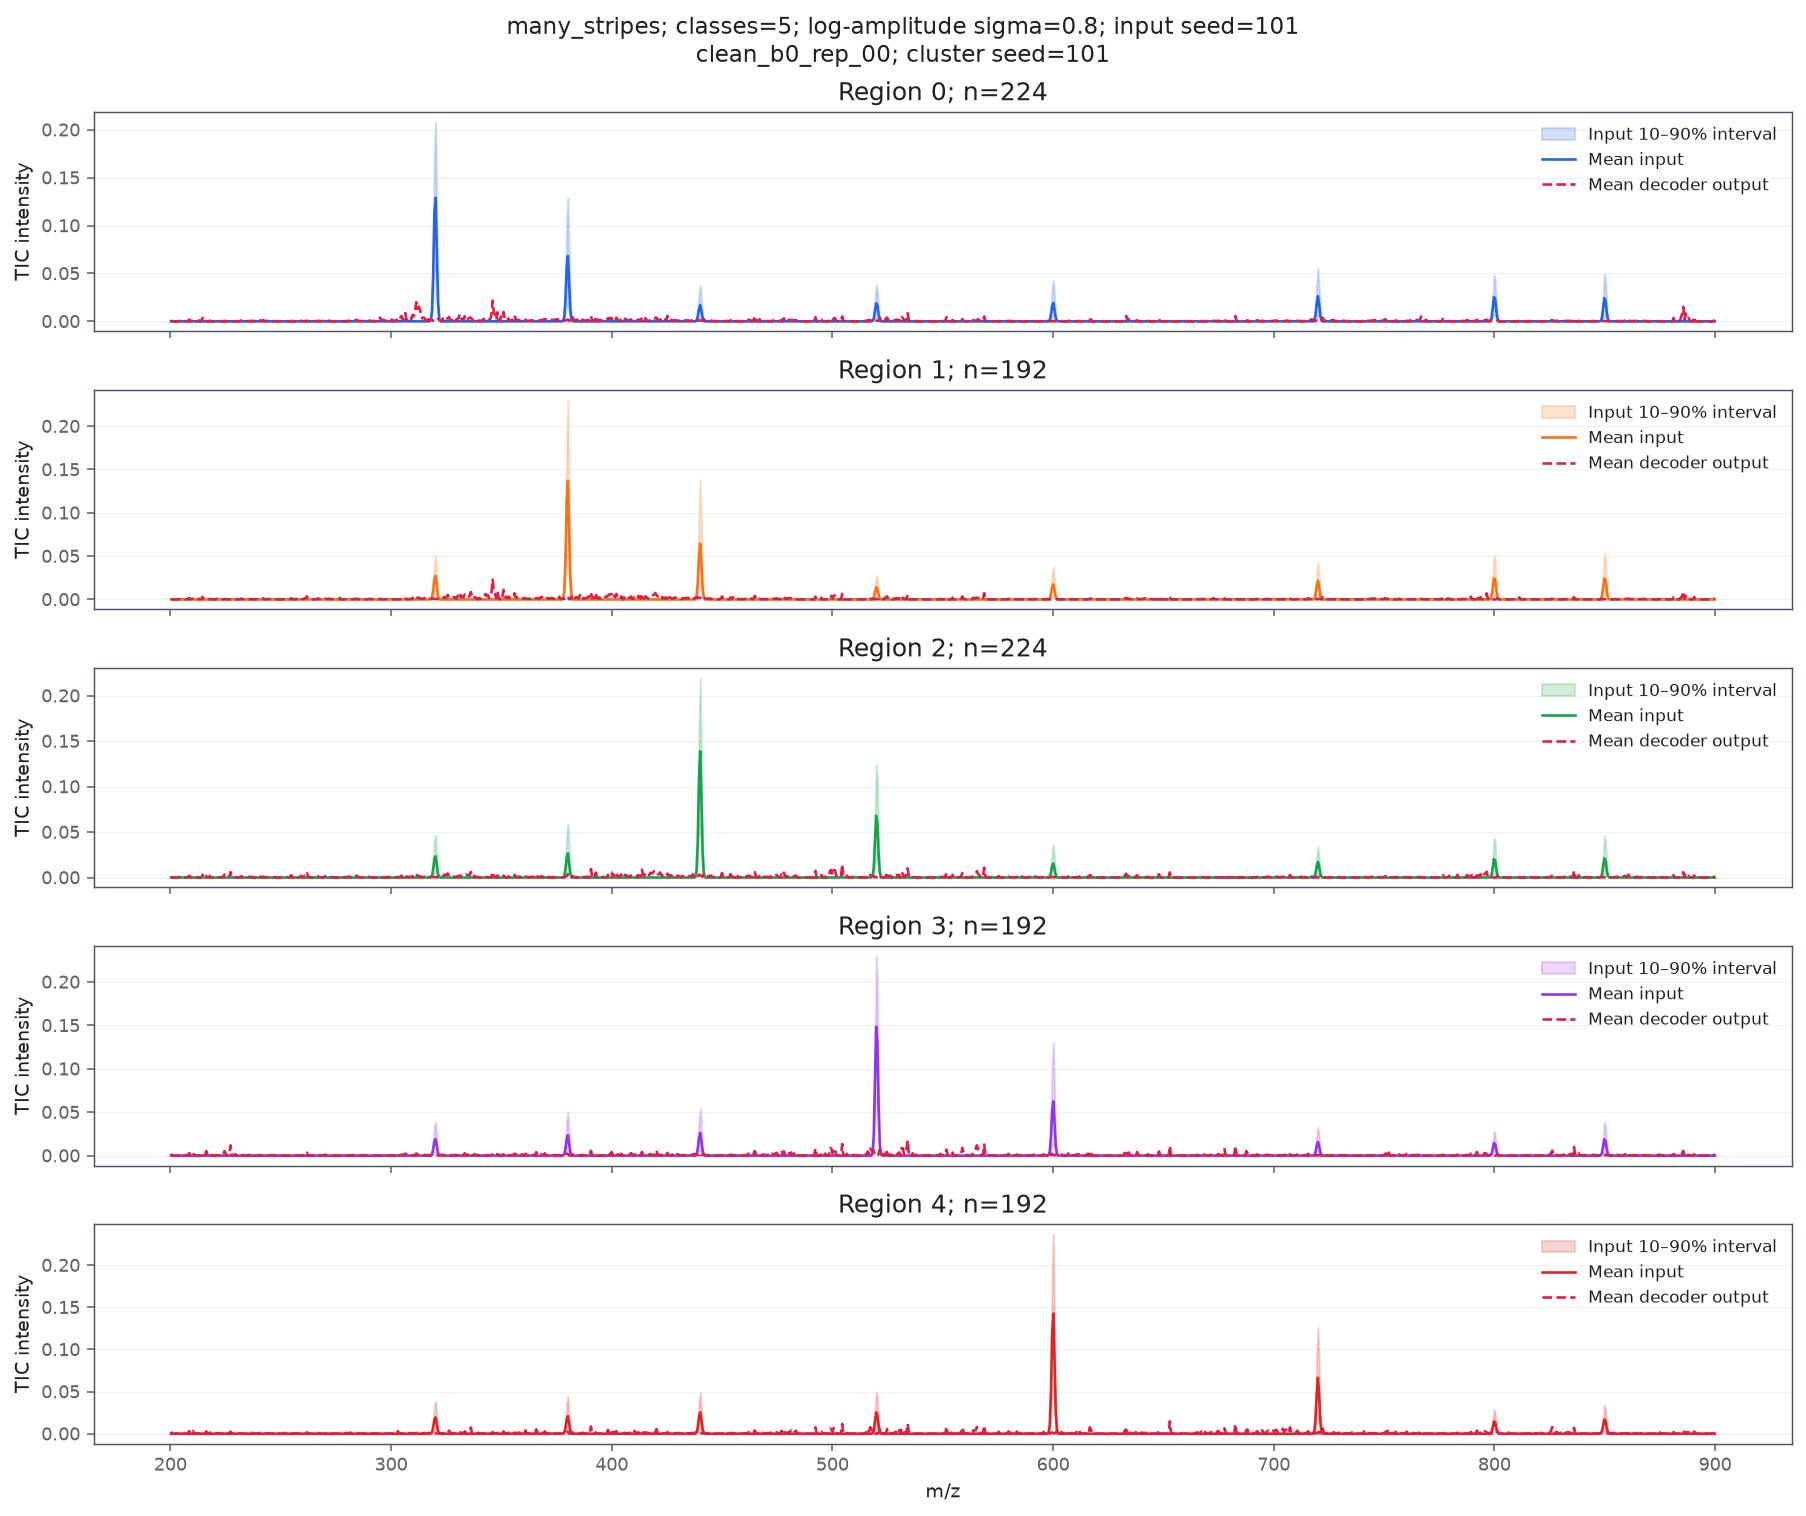

### pretraining_unfrozen_rep_00; amplitude noise=0.8

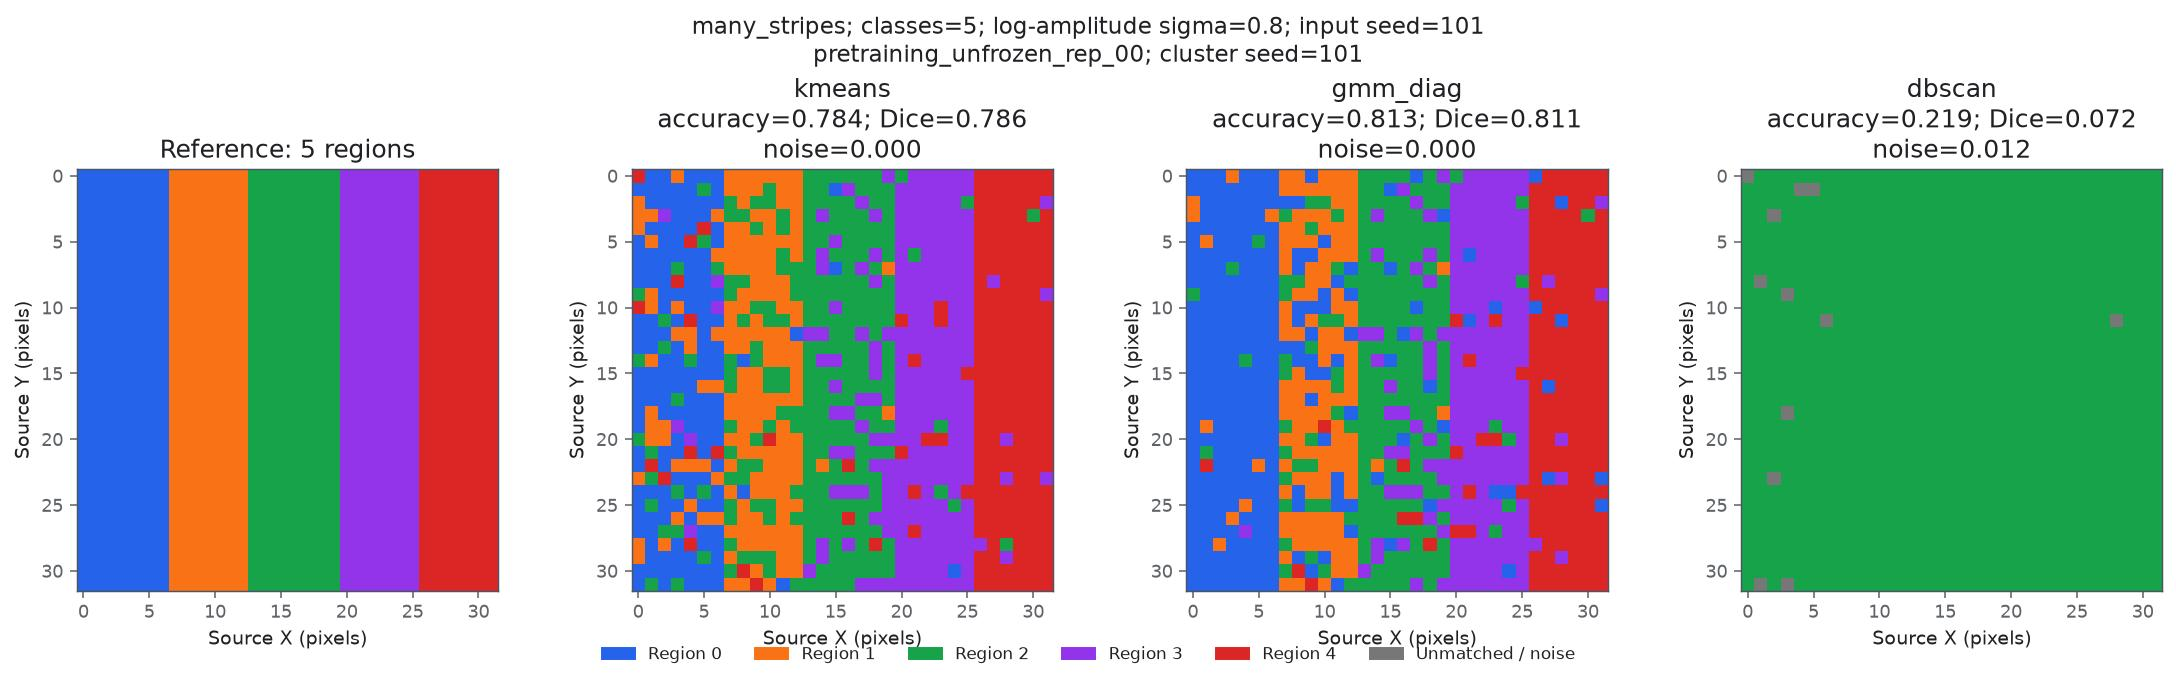

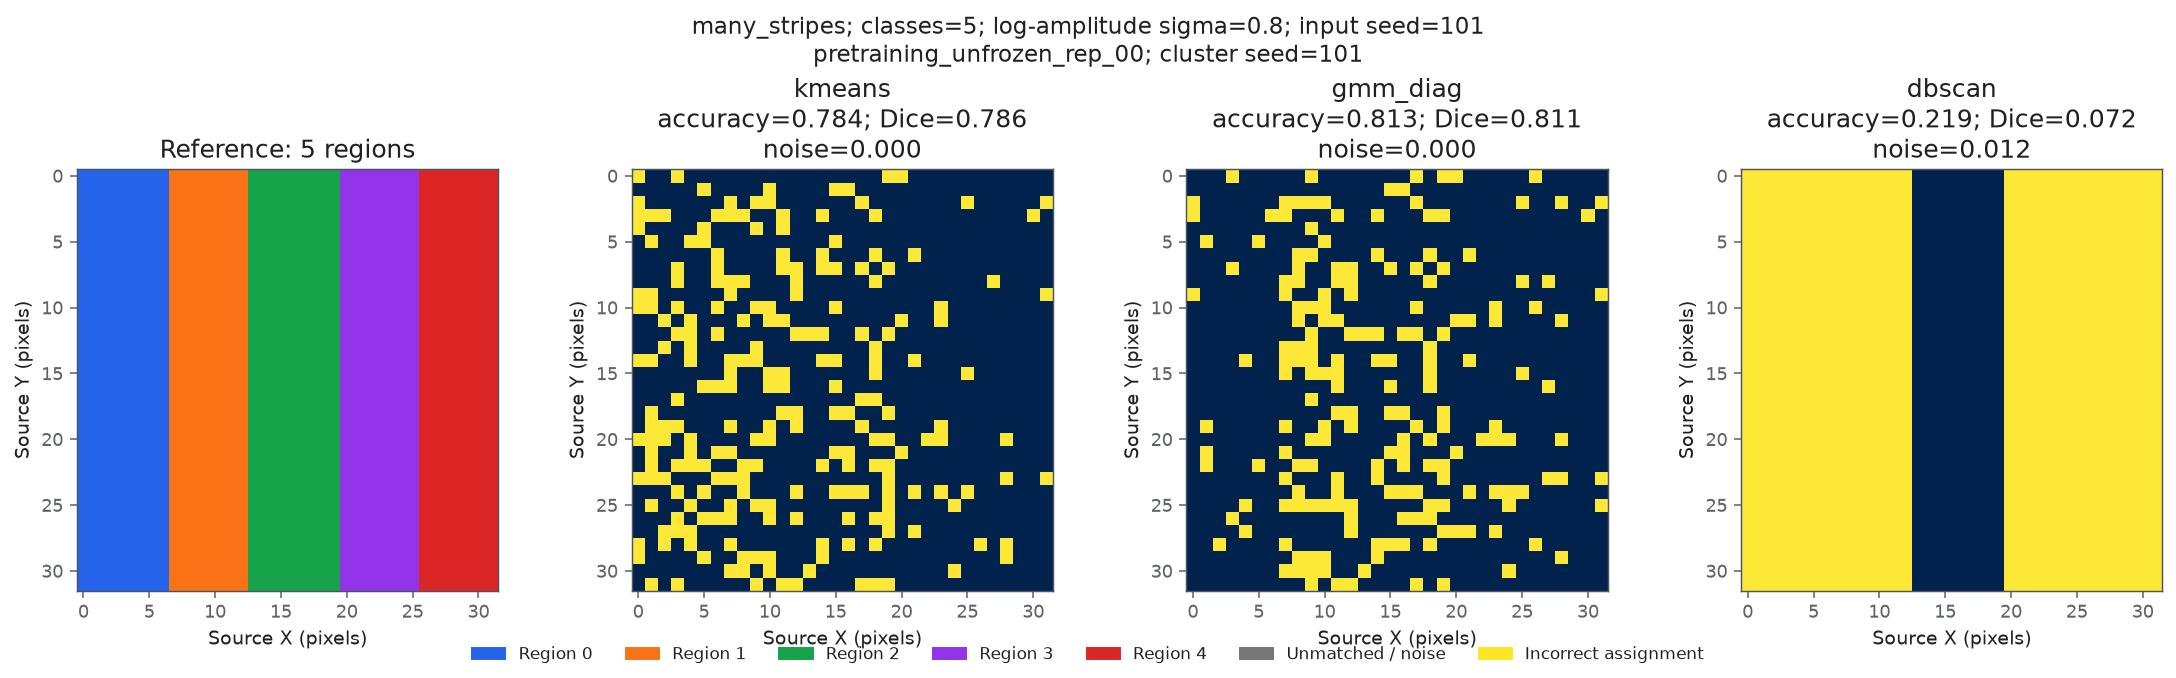

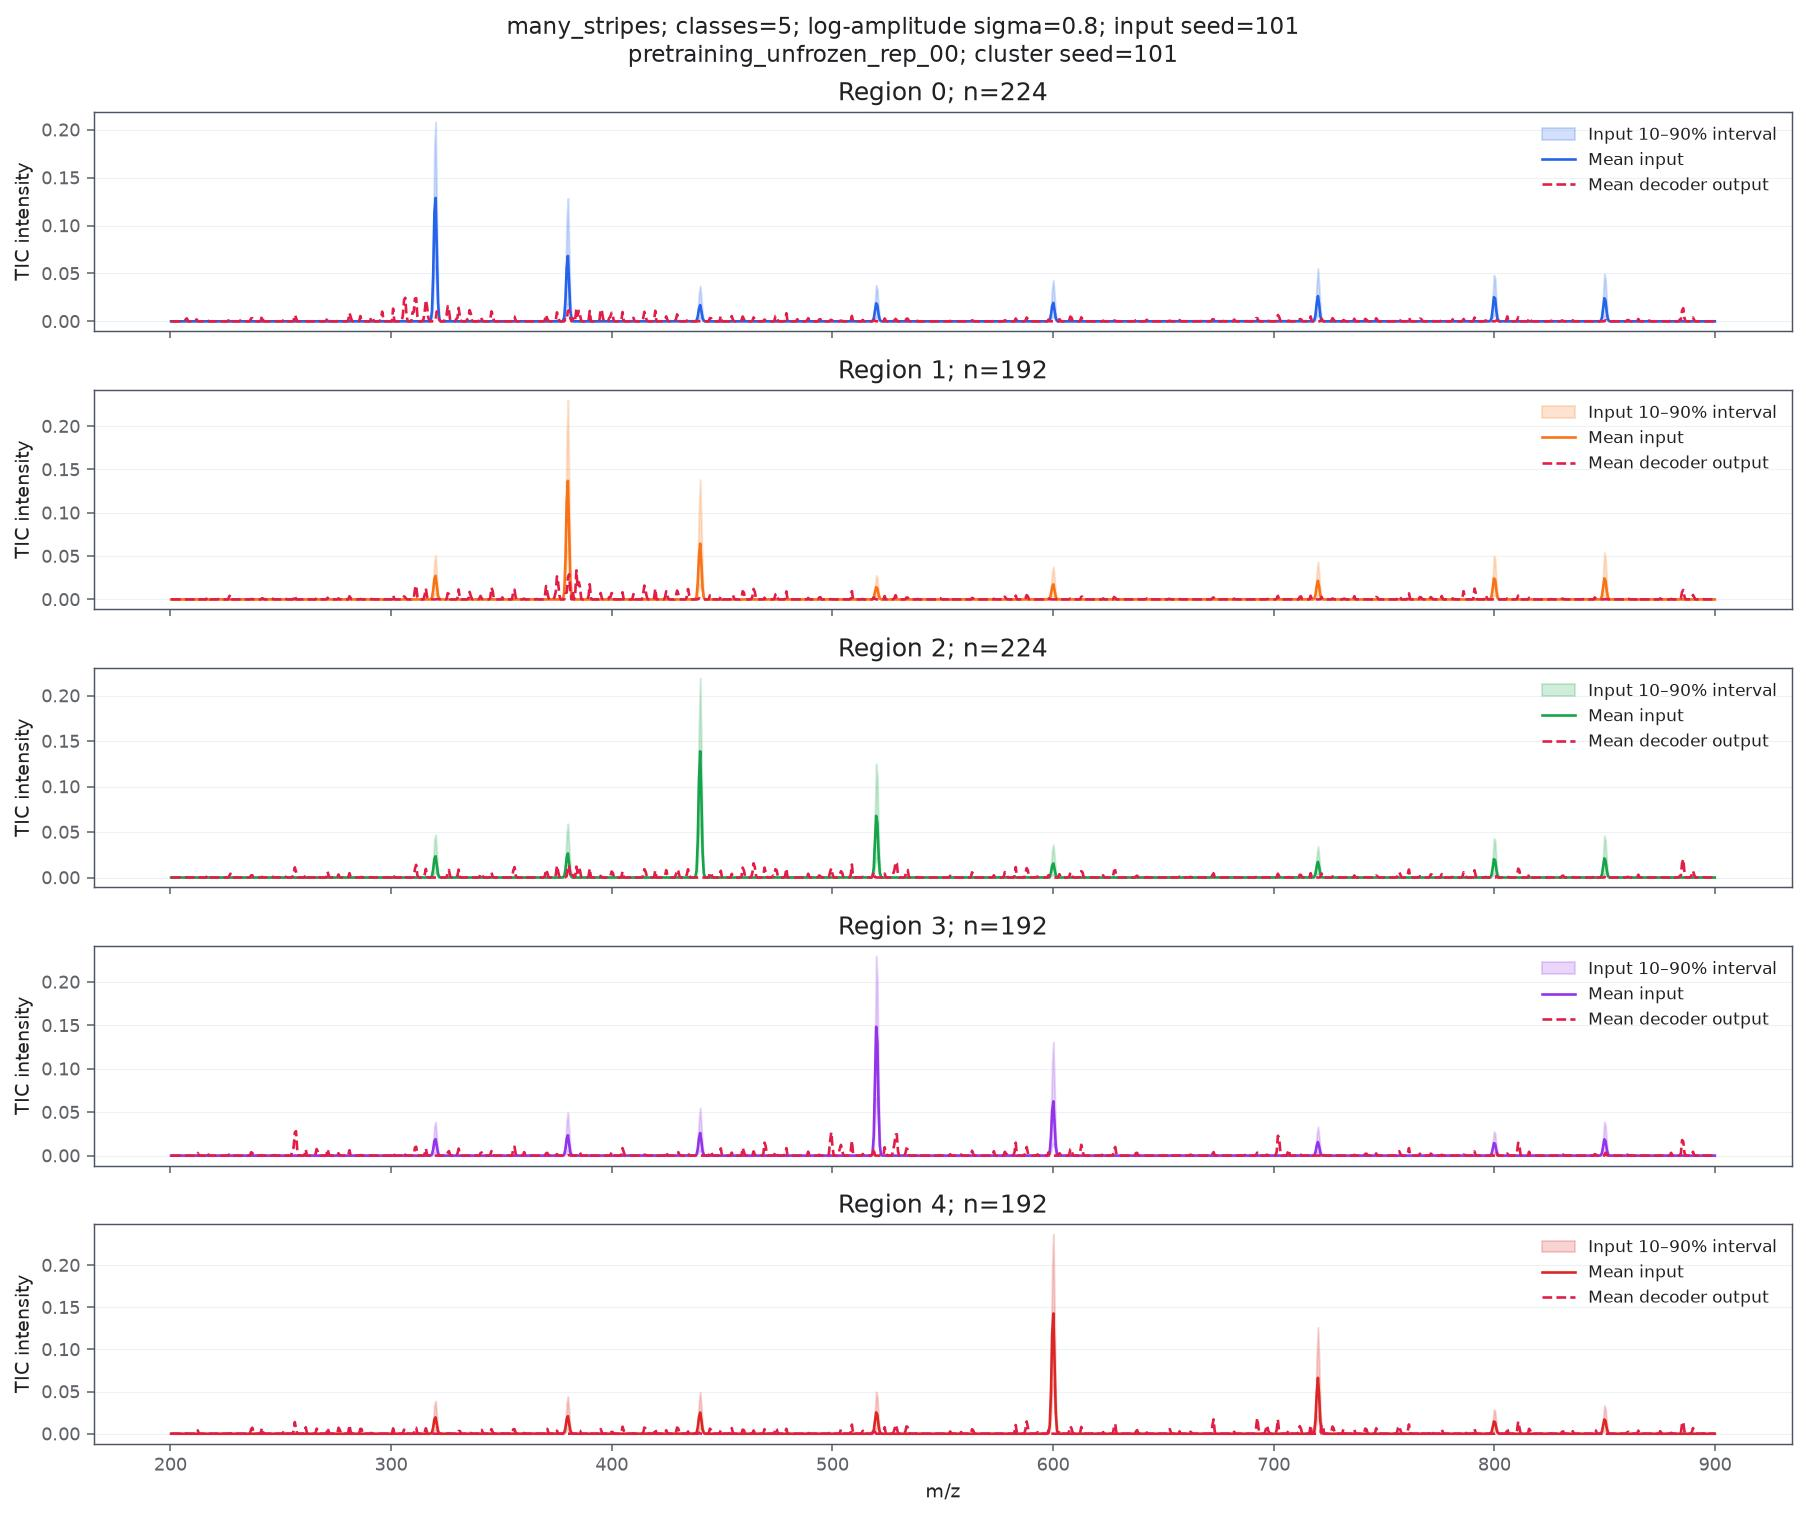

In [4]:
LAYOUT = "many_stripes"
NOISE = settings["spectral_partition_comparison"]["relative_amplitude_noise"][-1]
REPRESENTATIONS = ["raw_tic_spectra", "clean_b0_rep_00", "pretraining_unfrozen_rep_00"]
SHOW_ERRORS = True
SHOW_SPECTRA = True
selected = gallery[(gallery.layout == LAYOUT) & (gallery.noise == NOISE) & gallery.representation.isin(REPRESENTATIONS)]
for row in selected.itertuples():
    display(Markdown(f"### {row.representation}; amplitude noise={row.noise}"))
    display(Image(filename=str(results / "plots" / f"{row.plot_stem}.jpeg")))
    if SHOW_ERRORS:
        display(Image(filename=str(results / "plots" / f"{row.plot_stem}_errors.jpeg")))
    if SHOW_SPECTRA:
        display(Image(filename=str(results / "plots" / f"{row.plot_stem}_spectra.jpeg")))

## Five concentric spectral regions

### Methodology

#### Theoretical

The concentric_rings reference fixes region identity independently of the model representation. The ring exterior is unknown; region scores use only observed source pixels.

#### Implementation

The following cells read already-generated method, error and spectral-profile JPEGs. Noise level and selected representations are presentation controls; numerical results for every seed/model repetition remain available in the CSV. No inference or clustering executes here.

#### Figure descriptions

The first panel is the reference. The following panels compare all three clustering methods on the identical observation. A second figure shows assignment errors; spectral profiles reveal whether apparent tissue classes correspond to distinct spectra and what the decoder preserves.

### Remarks

Changing the displayed representation does not change the fixed scoring protocol.

### Notes

### raw_tic_spectra; amplitude noise=0.8

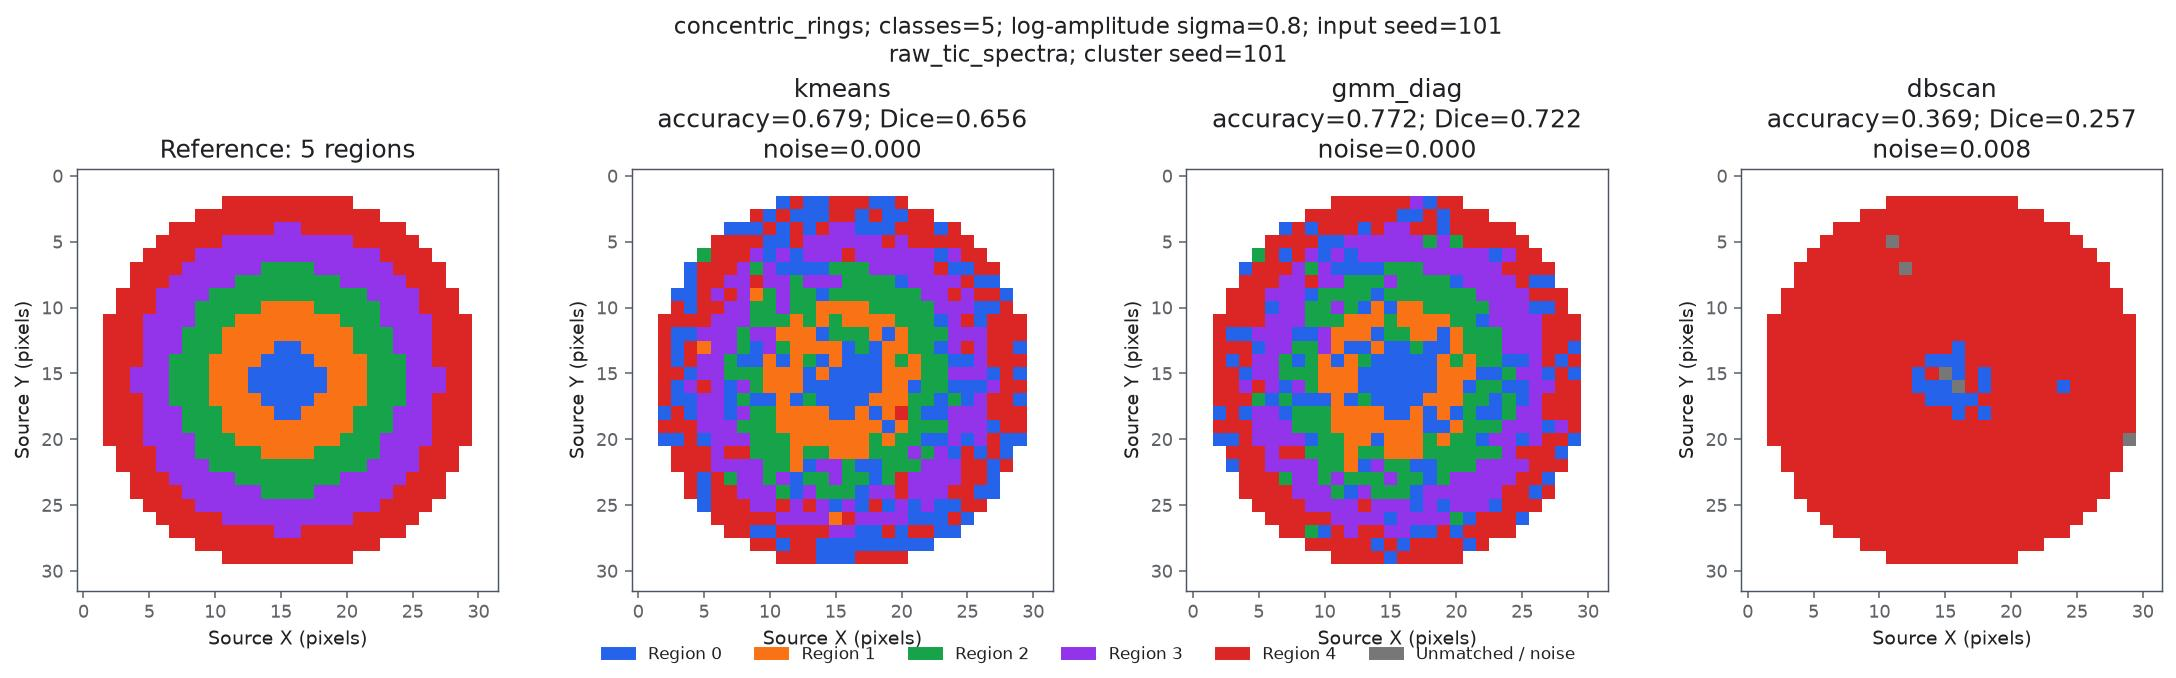

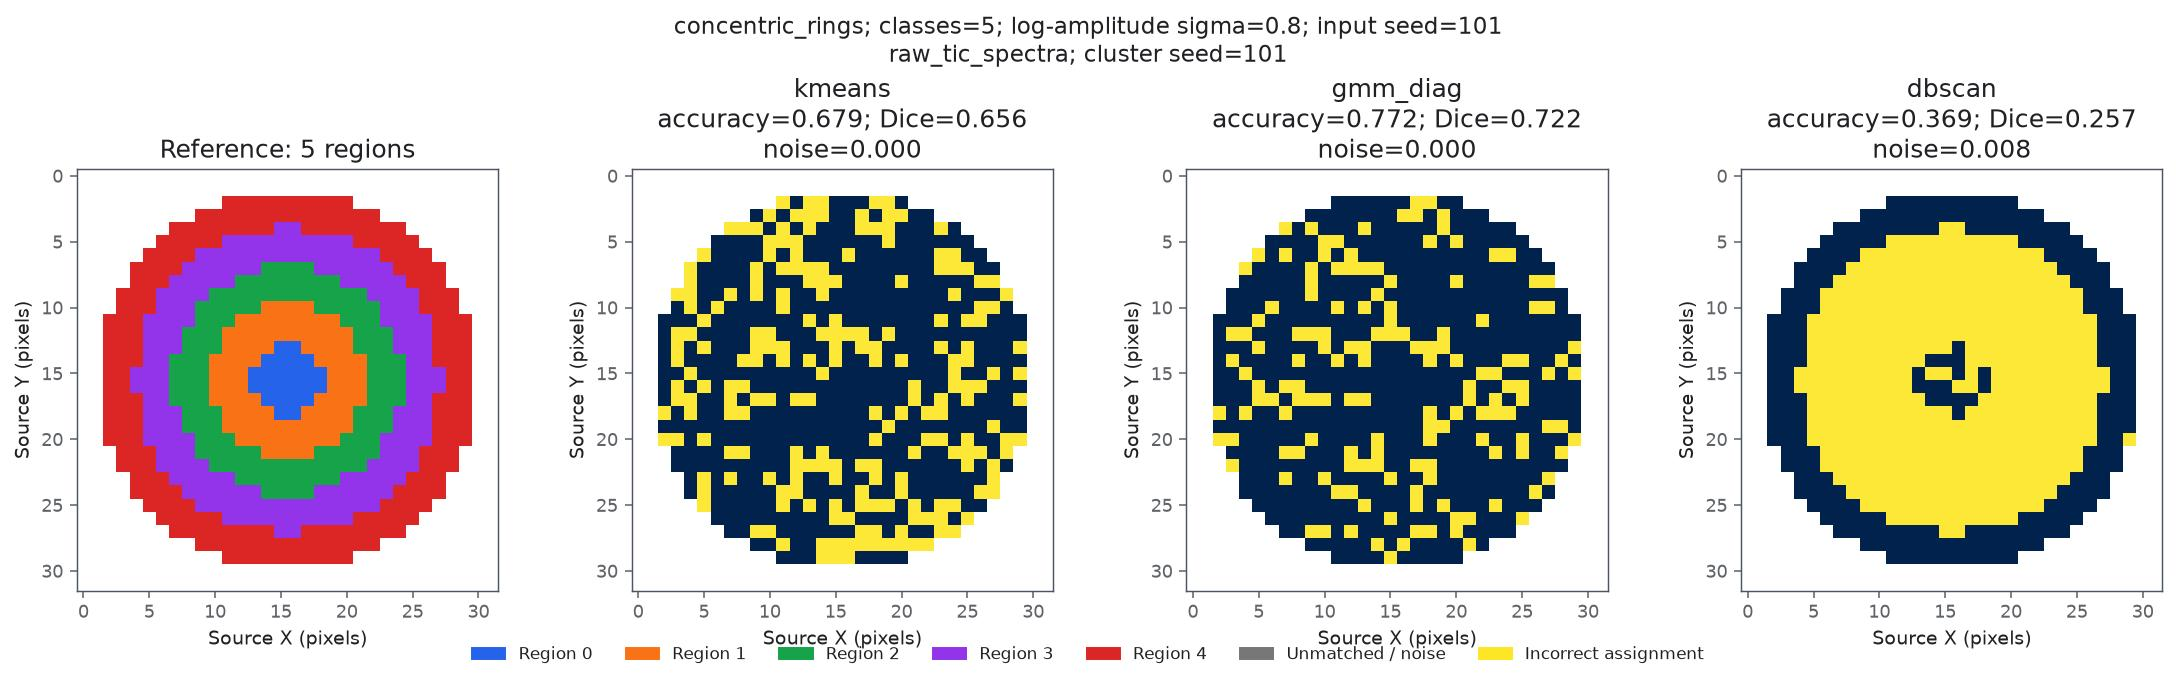

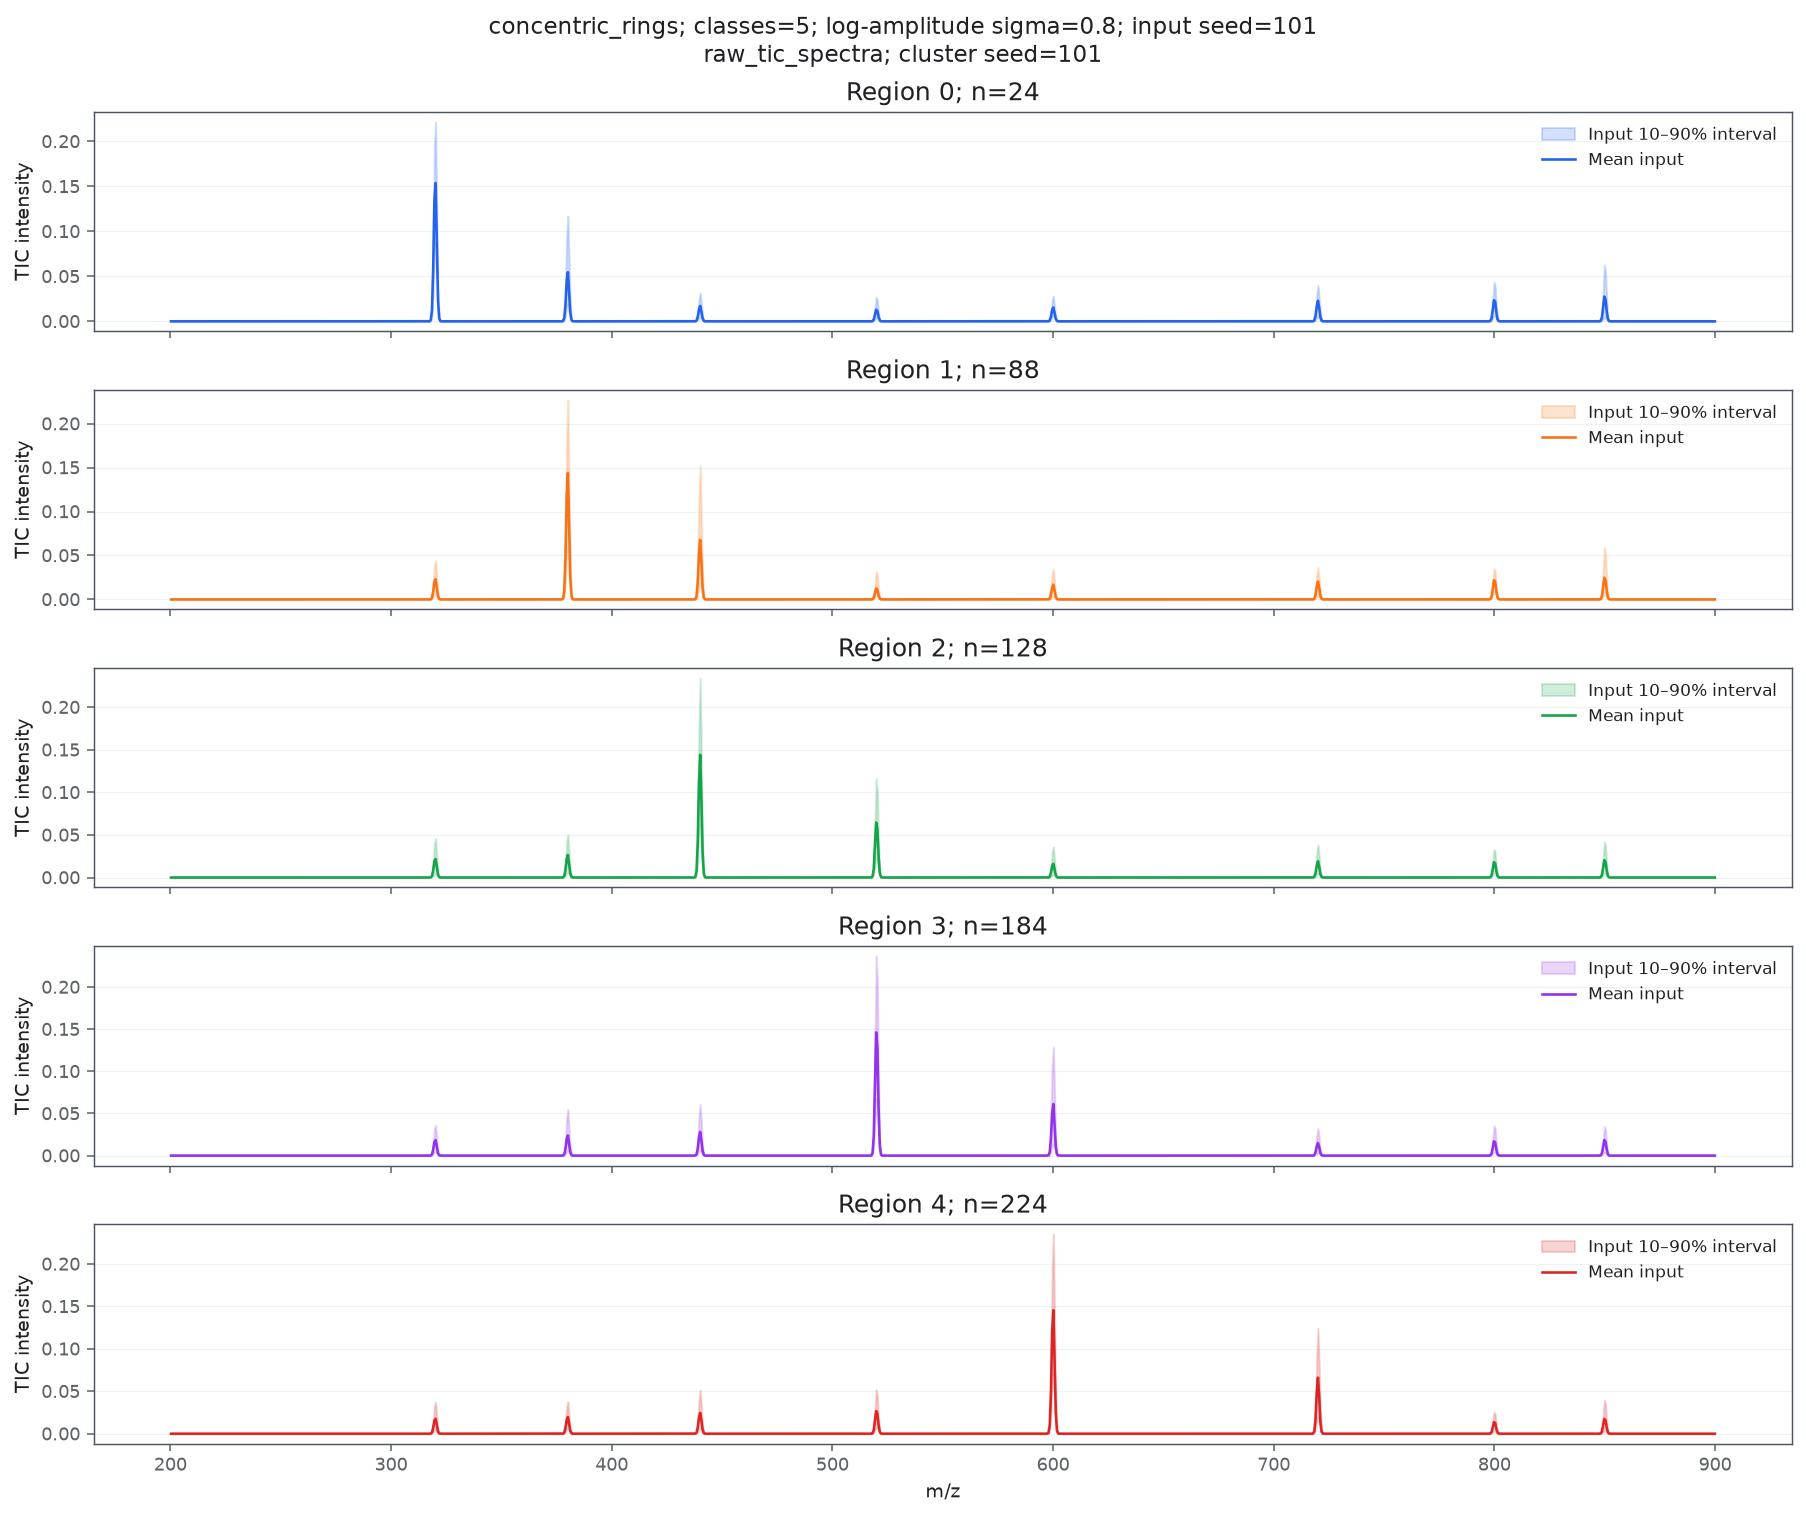

### clean_b0_rep_00; amplitude noise=0.8

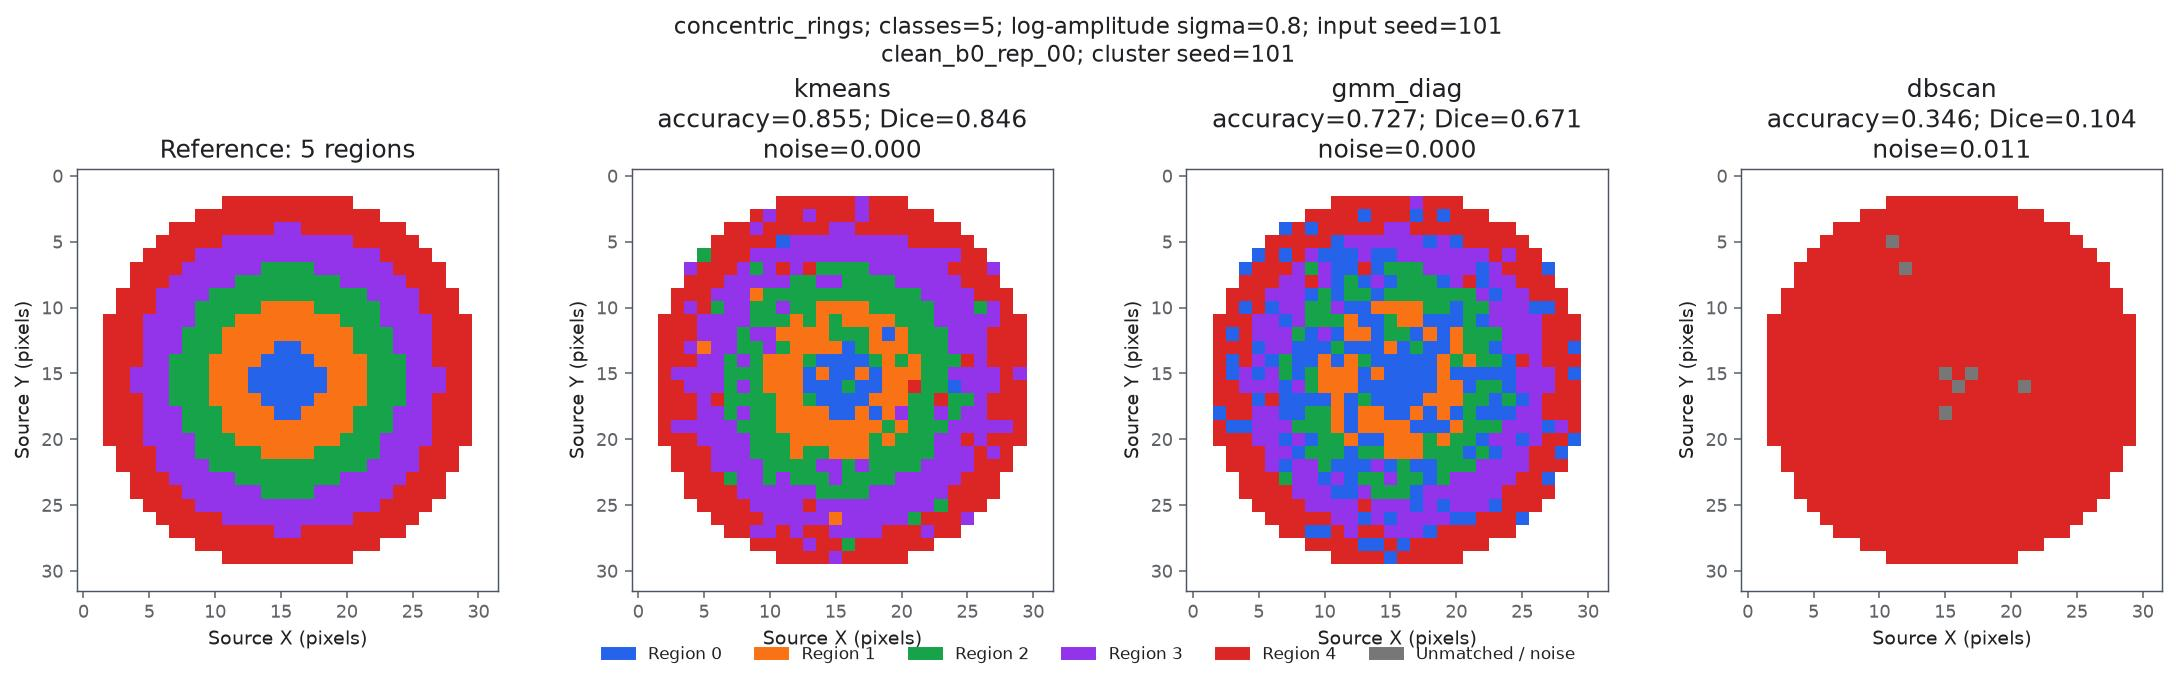

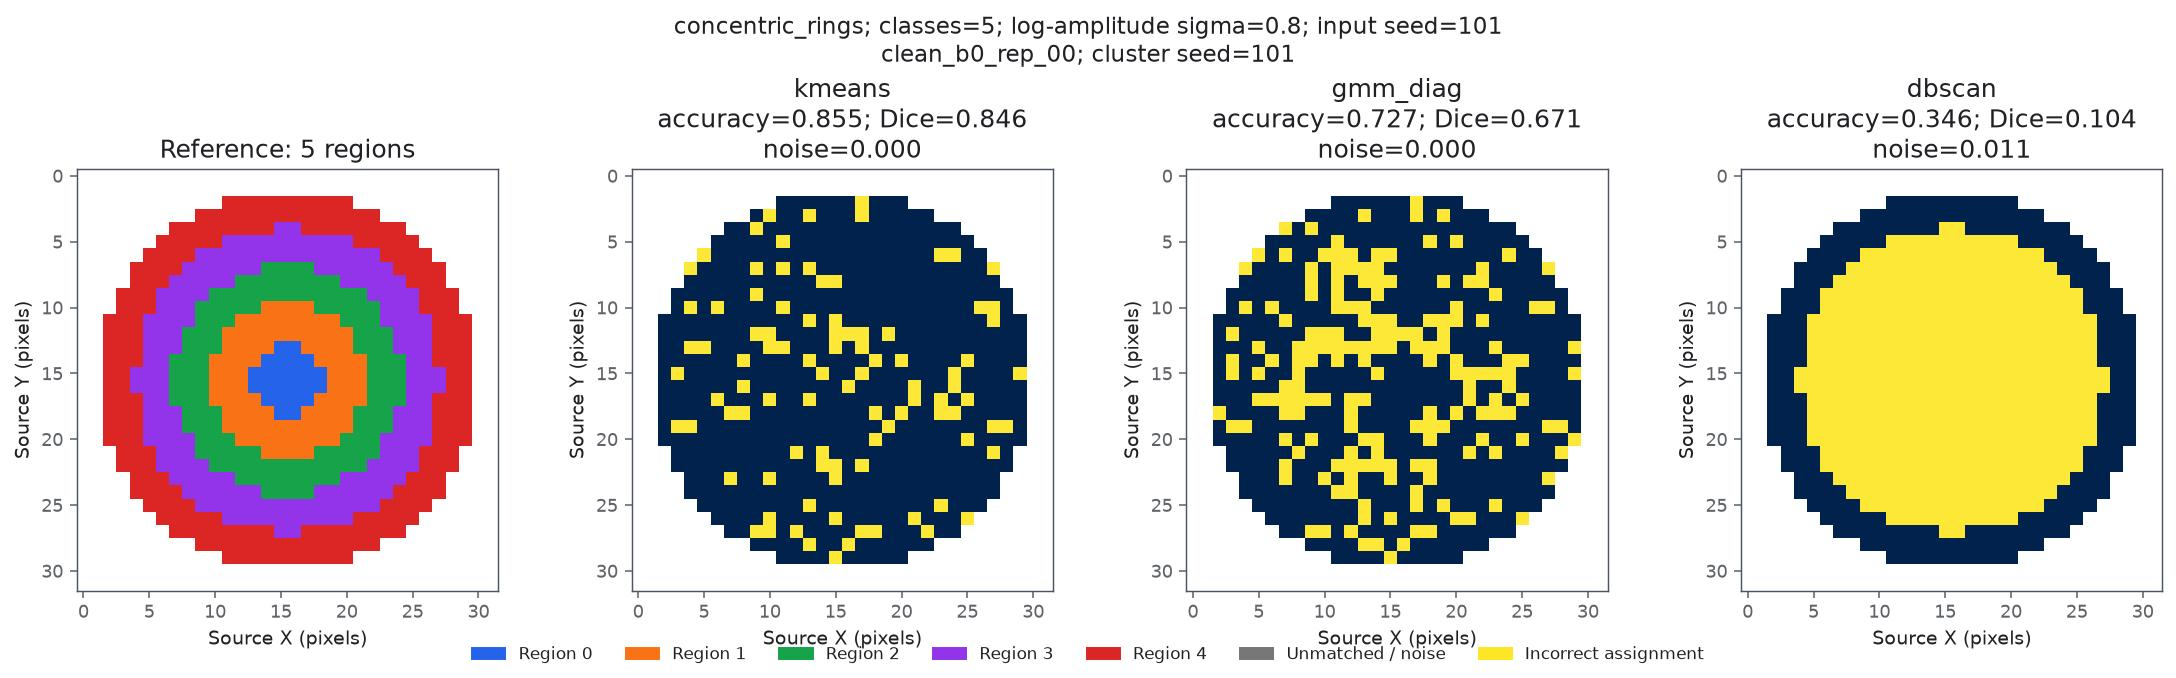

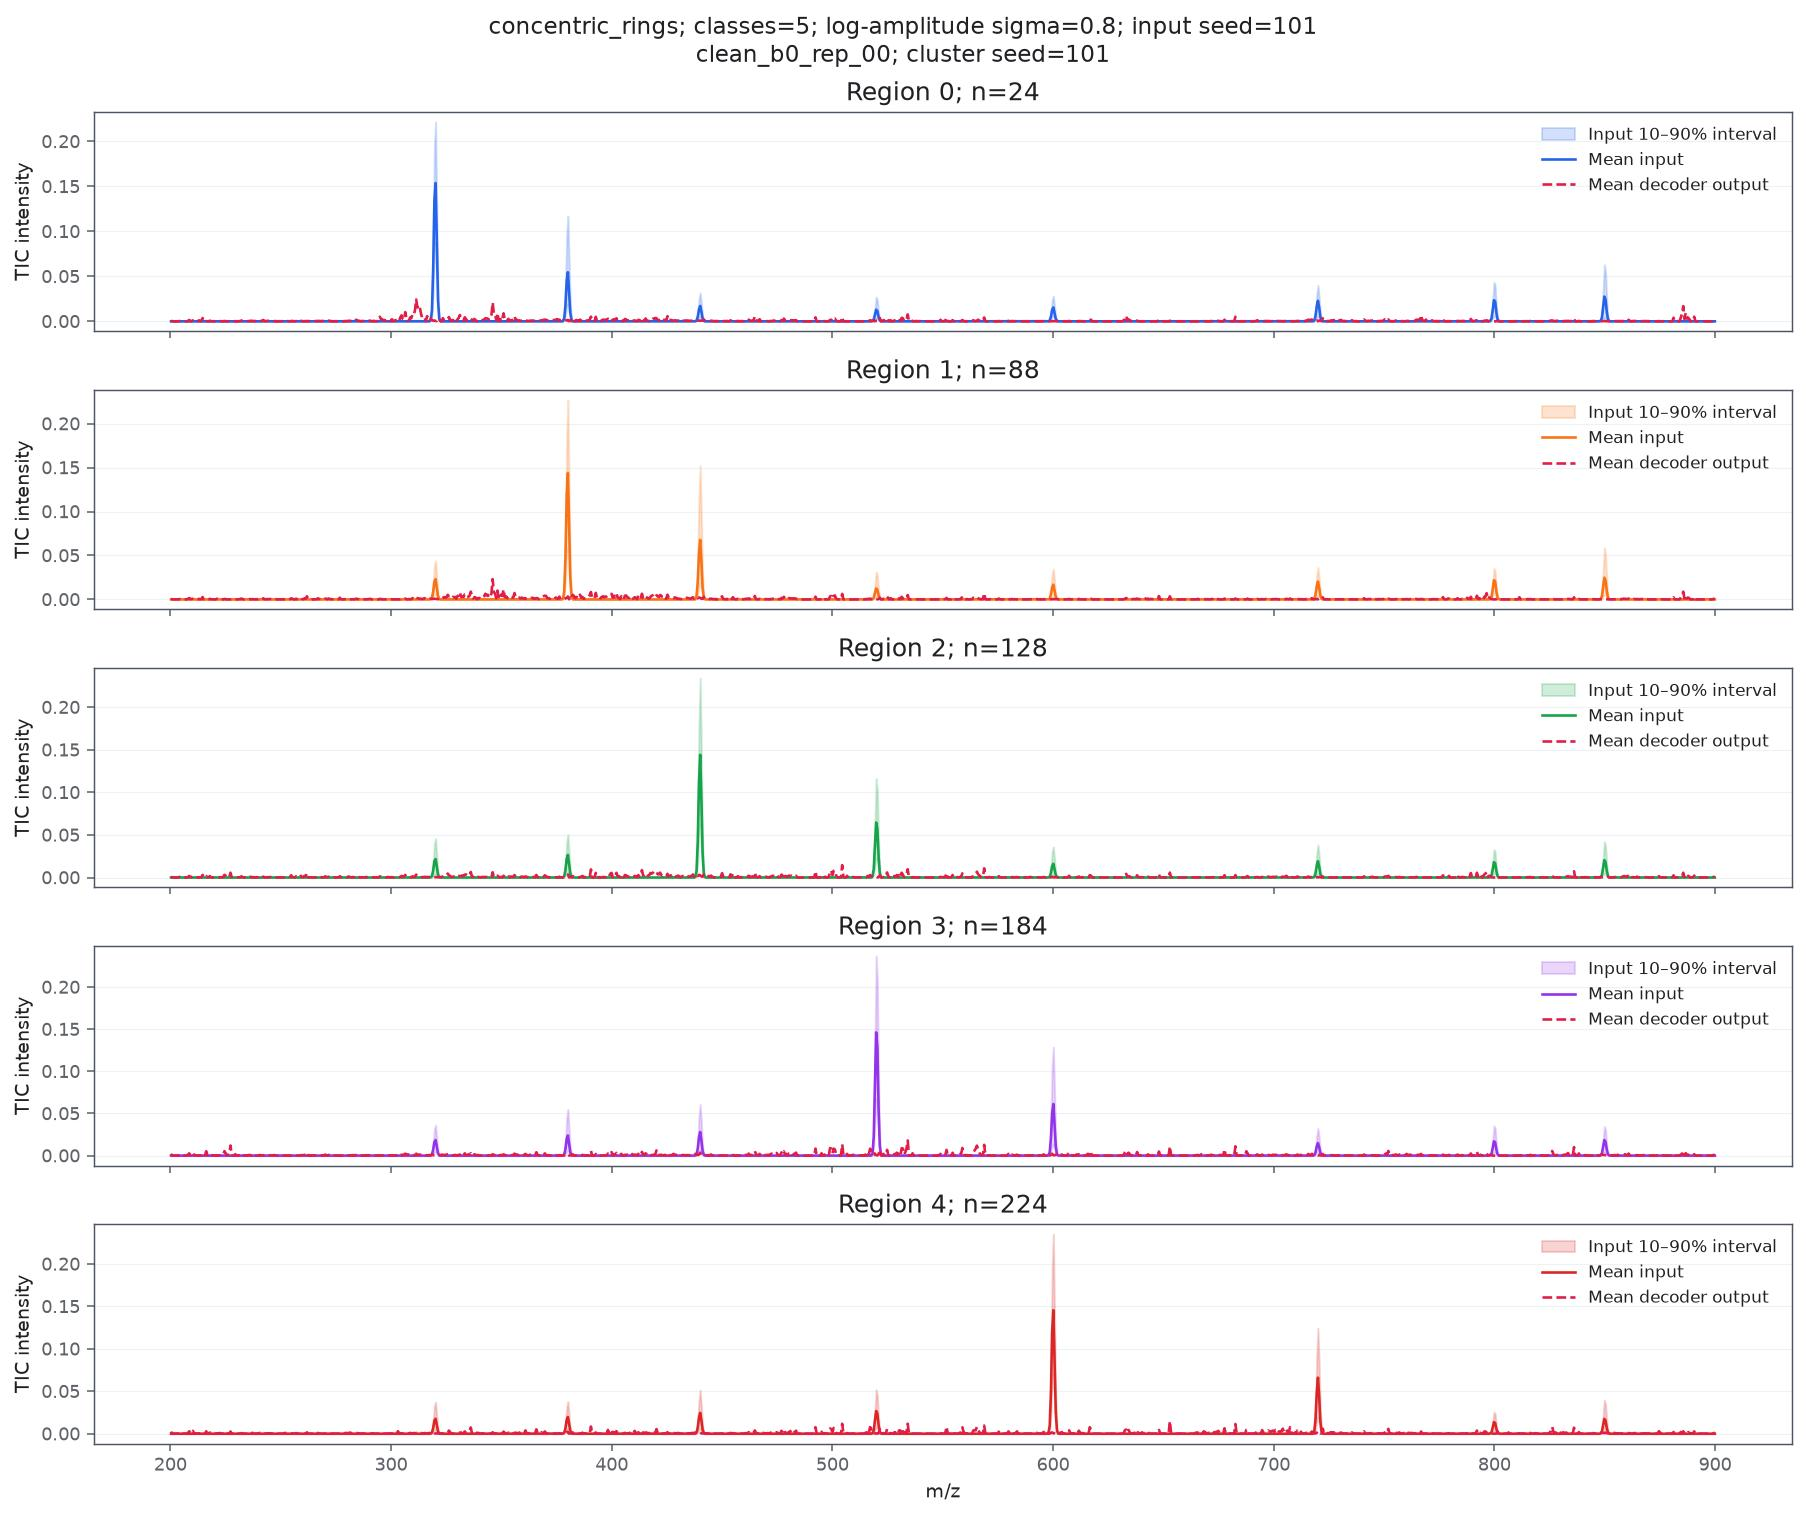

### pretraining_unfrozen_rep_00; amplitude noise=0.8

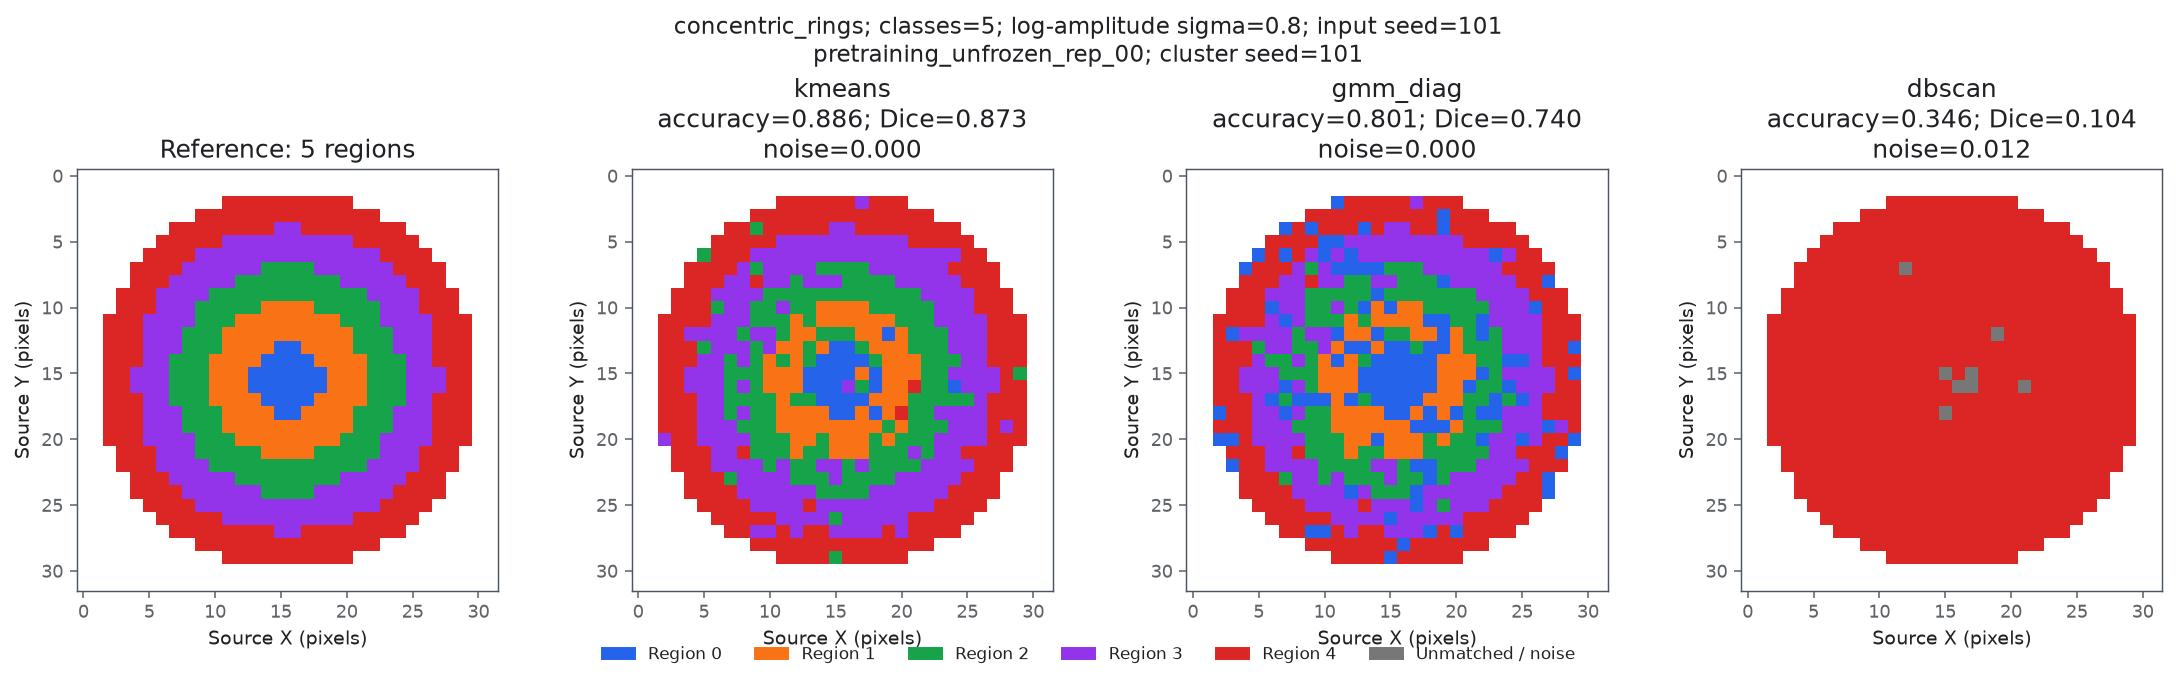

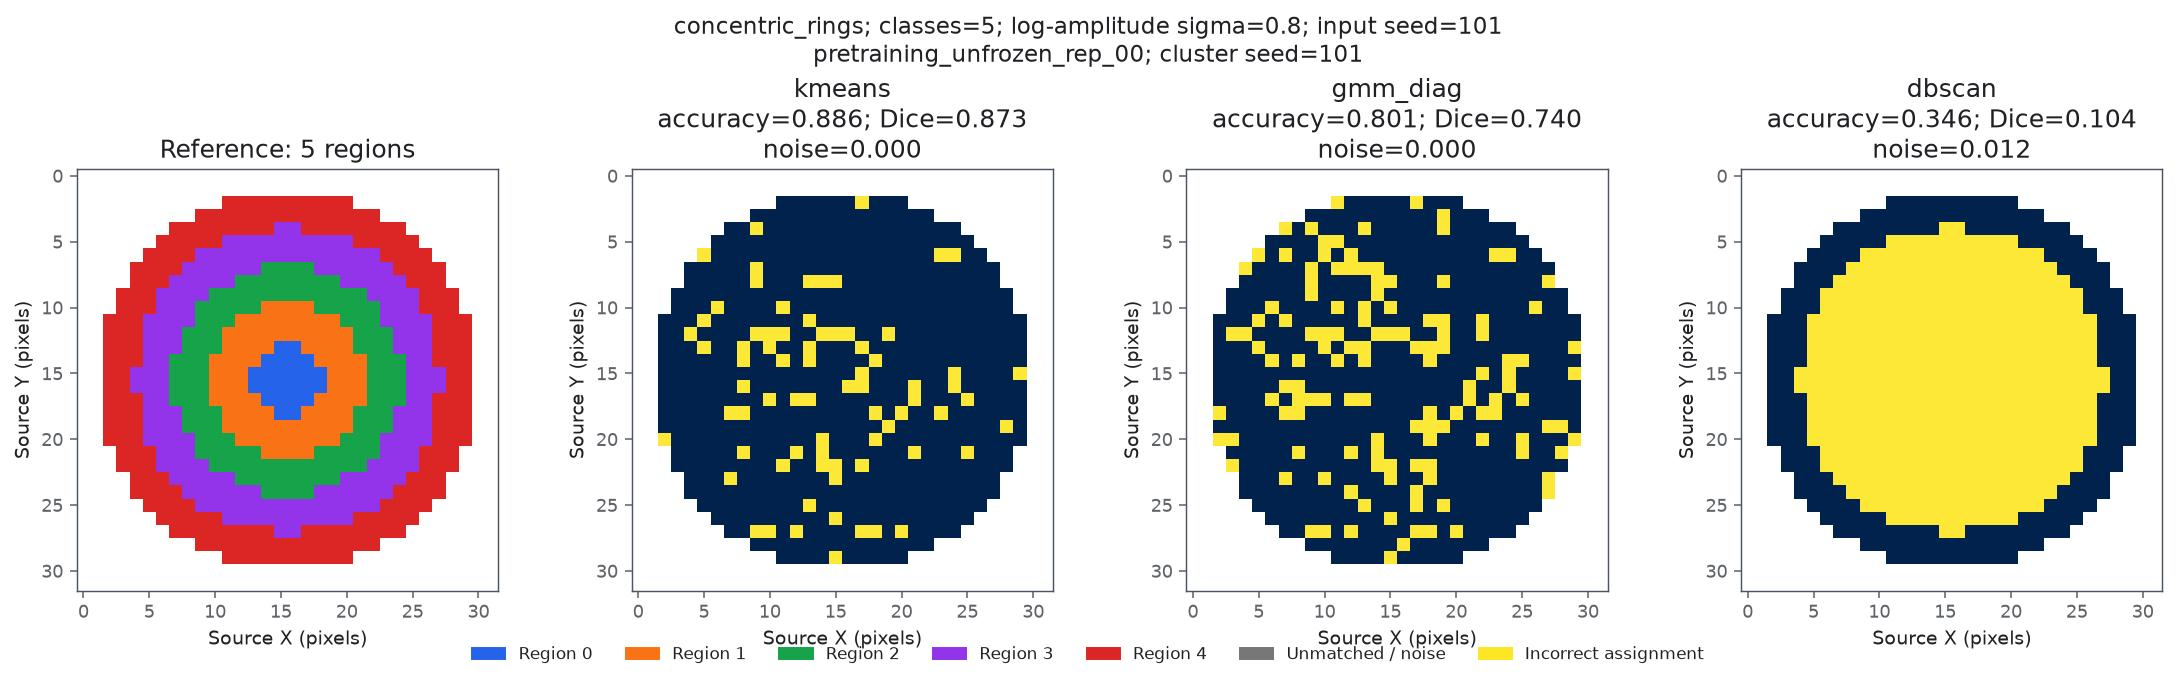

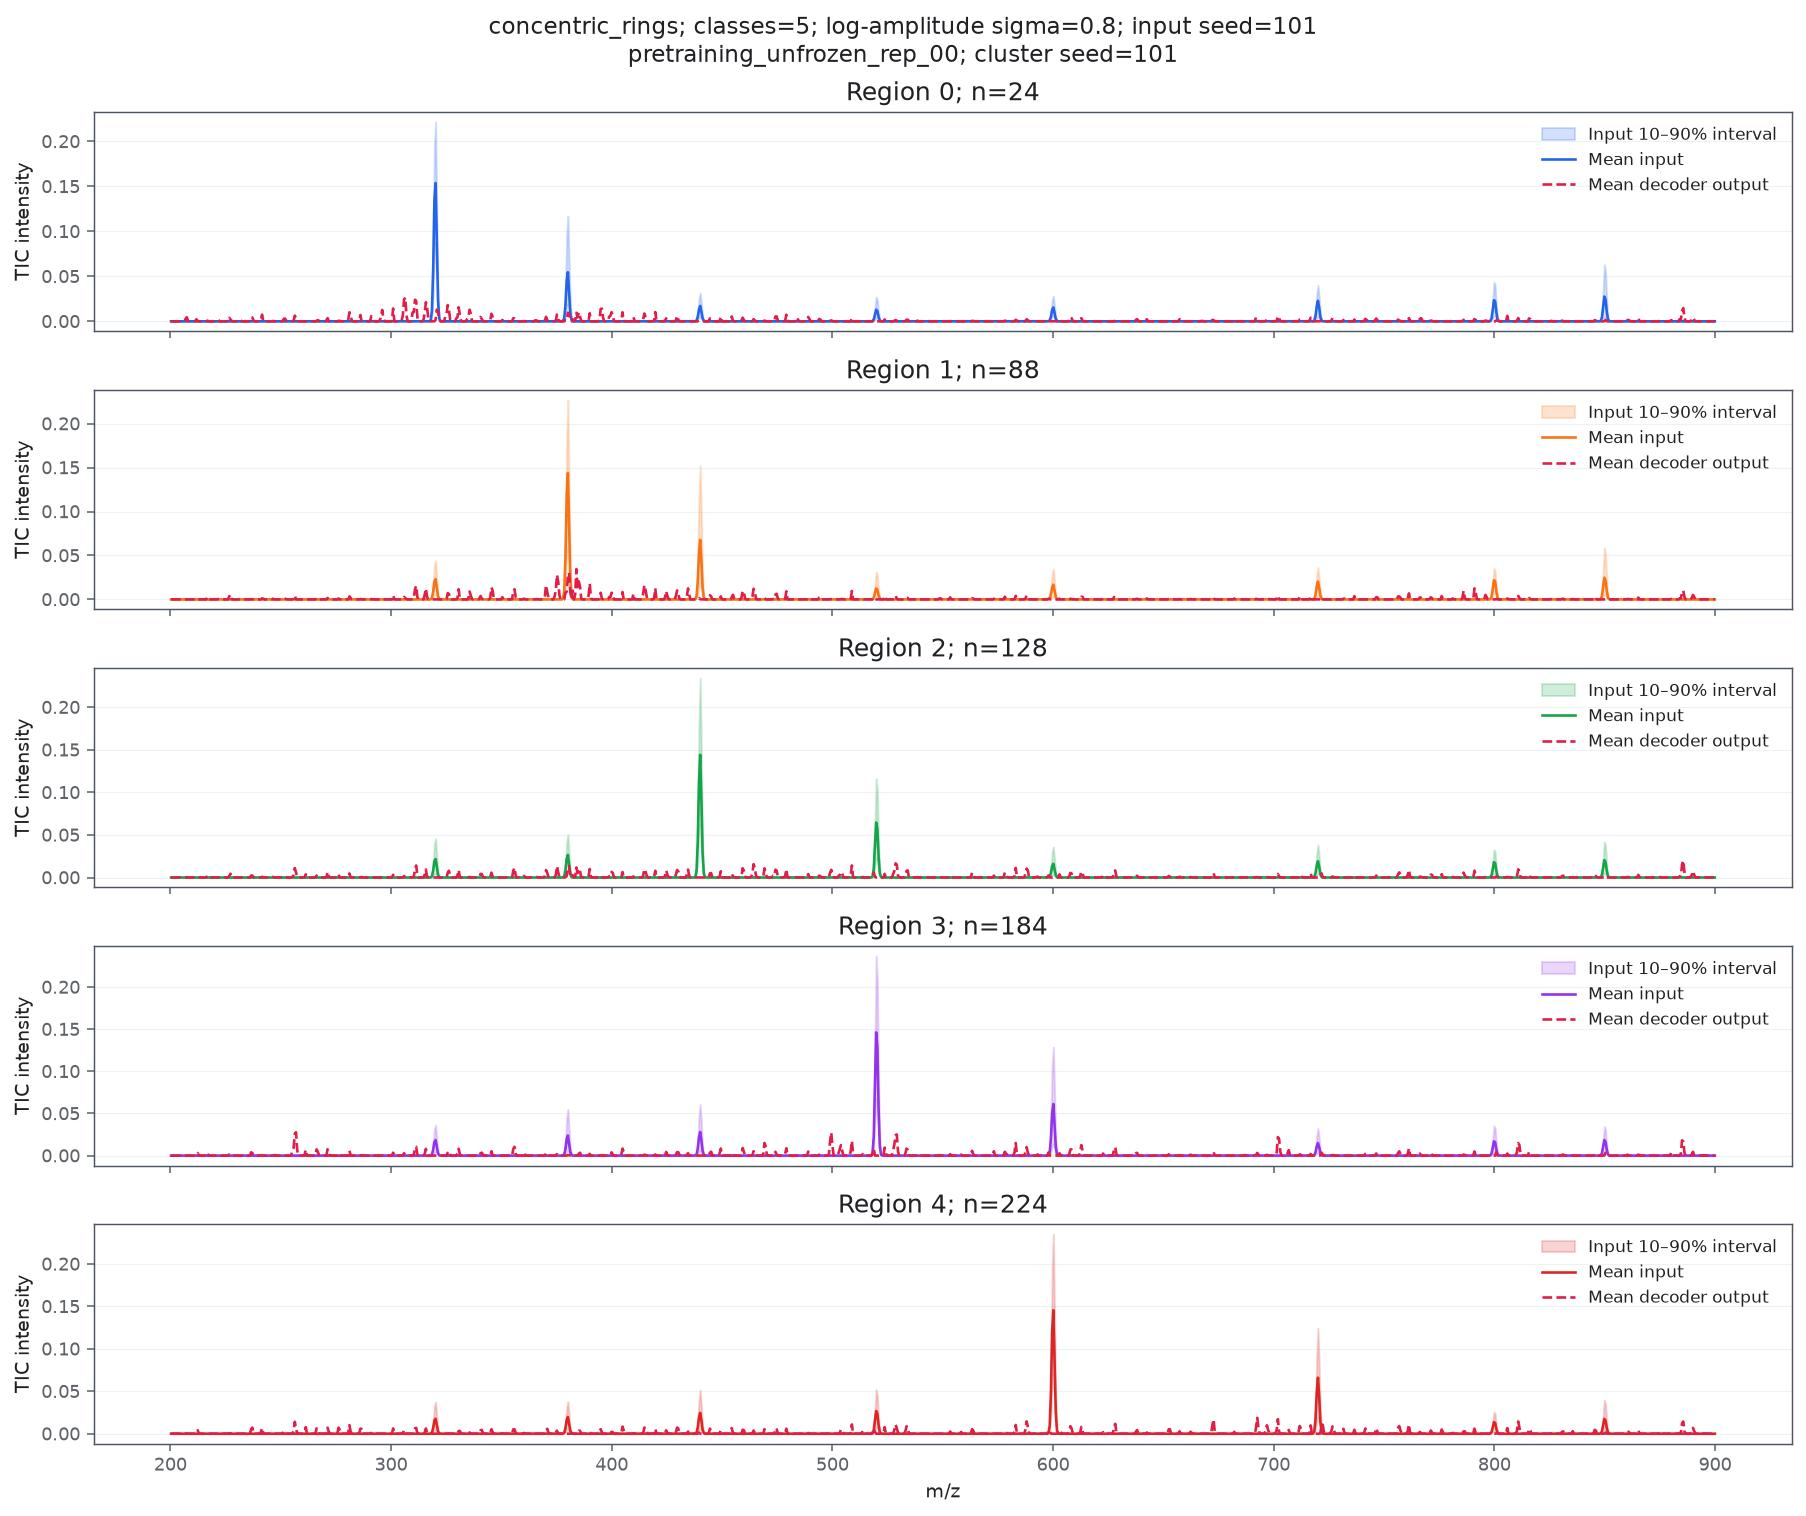

In [5]:
LAYOUT = "concentric_rings"
NOISE = settings["spectral_partition_comparison"]["relative_amplitude_noise"][-1]
REPRESENTATIONS = ["raw_tic_spectra", "clean_b0_rep_00", "pretraining_unfrozen_rep_00"]
SHOW_ERRORS = True
SHOW_SPECTRA = True
selected = gallery[(gallery.layout == LAYOUT) & (gallery.noise == NOISE) & gallery.representation.isin(REPRESENTATIONS)]
for row in selected.itertuples():
    display(Markdown(f"### {row.representation}; amplitude noise={row.noise}"))
    display(Image(filename=str(results / "plots" / f"{row.plot_stem}.jpeg")))
    if SHOW_ERRORS:
        display(Image(filename=str(results / "plots" / f"{row.plot_stem}_errors.jpeg")))
    if SHOW_SPECTRA:
        display(Image(filename=str(results / "plots" / f"{row.plot_stem}_spectra.jpeg")))

## Archived verifier controls

The following controls were produced before the CUDA-only requirement. These saved artifacts document metric behavior; they are not rerun by this notebook and are separate from the current GPU spectral/model comparison. CPU/CUDA checks shown here are historical evidence. Use `spectral_partitions` for the current run.

## Tissue assignment and boundaries

### Methodology

#### Theoretical

ARI/AMI compare partitions without cluster names. Rectangular maximum-intersection assignment supplies score-only class correspondence for accuracy, Dice and IoU. Unmatched clusters and HDBSCAN noise count as errors. Boundary F1 compares label-changing four-neighbour edges within a fixed distance; interior accuracy excludes the reference boundary band.

#### Implementation

The script creates a 24×24 two-region raster for each saved seed. The separable latent has low noise; the mixed latent has larger noise. Native-latent K-means, sklearn HDBSCAN and the existing GMM run with fixed settings. The full per-seed table preserves variation. Perfect, collapsed and all-noise controls check expected accuracies 1, 0.5 and 0. Distance tolerance is in synthetic raster pixels, not confirmed micrometres.

#### Figure descriptions

The distribution figure shows K-means matched assignment accuracy for separable and mixed synthetic inputs; points retain individual repetitions. The three-panel example shows reference region, matched clusters with consistent class colours, and binary assignment errors (yellow incorrect). Both axes are source-grid pixel positions; unknown is excluded consistently.

### Remarks

Covered-only HDBSCAN scores may be optimistic when most pixels become noise. The full score and noise fraction remain primary. K=2 is a fixture definition, not a tissue recommendation.

### Notes

,fixture,model_seed,method,seed,matched_accuracy,macro_dice,ari,noise_fraction,boundary_f1
0,separable,101,kmeans,101,1.000000,1.000000,1.000000,0.000000,1.000000
1,separable,101,kmeans,102,1.000000,1.000000,1.000000,0.000000,1.000000
2,separable,101,kmeans,103,1.000000,1.000000,1.000000,0.000000,1.000000
3,separable,101,hdbscan,101,1.000000,1.000000,1.000000,0.000000,1.000000
4,separable,101,hdbscan,102,1.000000,1.000000,1.000000,0.000000,1.000000
5,separable,101,hdbscan,103,1.000000,1.000000,1.000000,0.000000,1.000000
6,separable,101,gmm,101,1.000000,1.000000,1.000000,0.000000,1.000000
7,separable,101,gmm,102,1.000000,1.000000,1.000000,0.000000,1.000000
8,separable,101,gmm,103,1.000000,1.000000,1.000000,0.000000,1.000000
9,mixed,101,kmeans,101,0.875000,0.874994,0.561738,0.000000,0.407507


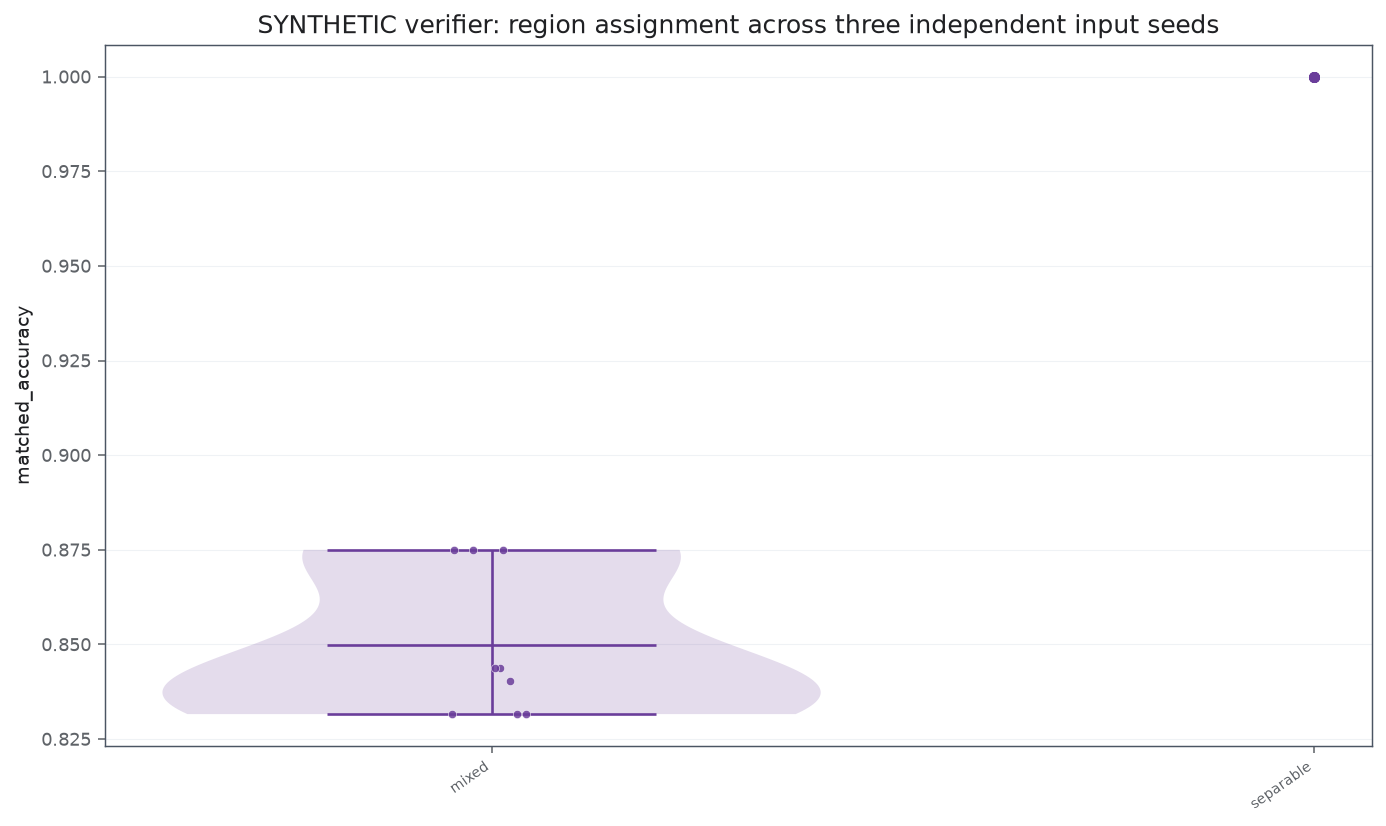

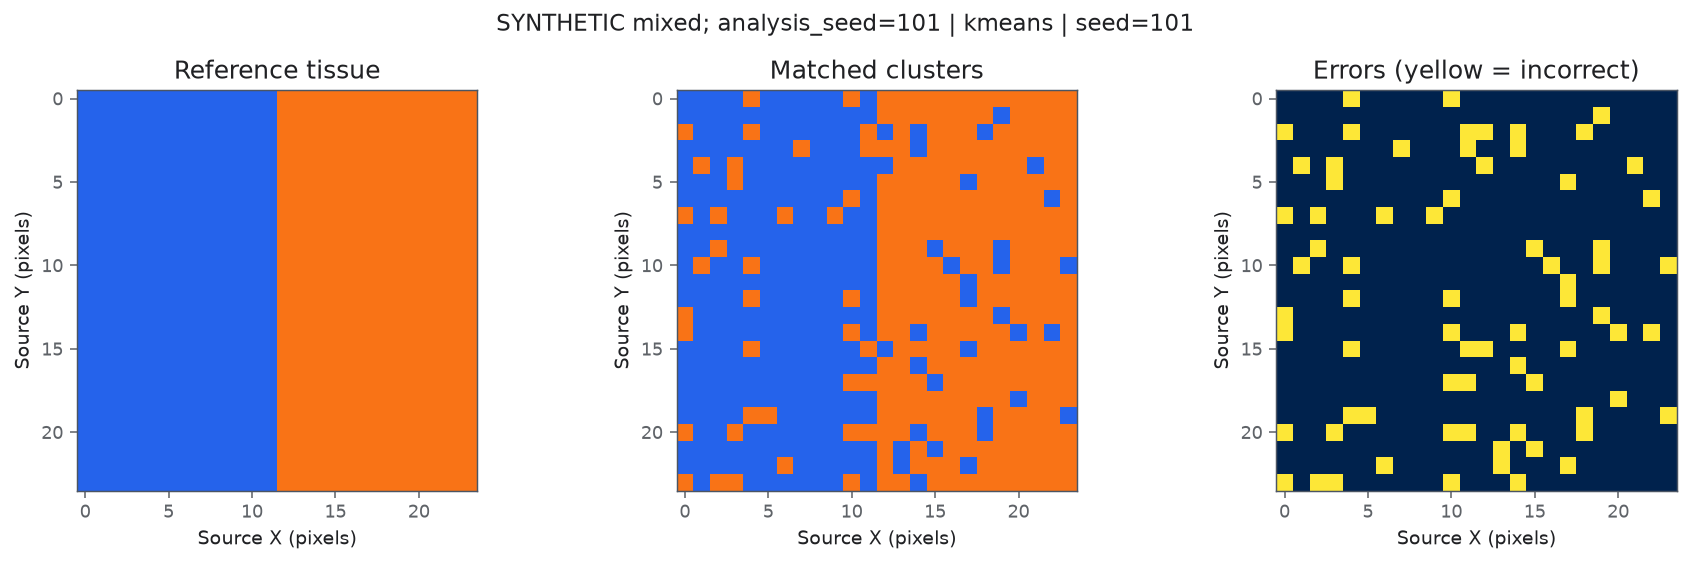

In [6]:
METHOD = "kmeans"
FIXTURE = "mixed"
SEED = settings["seeds"][0]
table = load_table(settings, "fixture_segmentation_scores.csv")
display(table[["fixture", "model_seed", "method", "seed", "matched_accuracy", "macro_dice", "ari", "noise_fraction", "boundary_f1"]])
display(Image(filename=str(results / "plots" / "fixture_segmentation_accuracy.png")))
case = results / "cases" / f"{FIXTURE}_seed_{SEED}"
display(Image(filename=str(case / "plots" / f"segmentation_{METHOD}.png")))

## Precision, reconstruction tails and chemical clustering

### Methodology

#### Theoretical

Prediction precision is TP/(TP+FP) at a frozen threshold; recall prevents an empty predictor from appearing useful. Reconstruction MAE is averaged across M features per spectrum. Feature rarity is defined by prevalence frozen outside external test. Positive-only relative error excludes zero targets; absolute error retains hallucinations. Chemical overlap treats each multilabel class separately and never equates chemistry with anatomy.

#### Implementation

The script reuses maintained prediction/reconstruction metrics. It records per-spectrum errors, q95/q99/max, per-feature errors and worst spectrum-feature pairs. A rare peak is deliberately removed. Chemical profile heatmaps show observed-positive fractions by cluster; supervised overlap is unavailable for incomplete PU annotation. The synthetic fixture has complete known labels. No SVM is fitted on external labels.

#### Figure descriptions

The worst-case plot overlays input and reconstruction over m/z, with signed residuals below. The error distribution shows feature MAE conditioned on frozen rarity. The chemical heatmap shows class index on columns, cluster ID on rows and observed positive fractions in the cells. Canonical CSVs retain all values, including undefined entries.

### Remarks

The inherited spectral-angle convention gives pi/2 for zero-norm pairs. Precision against incomplete labels does not establish true molecular specificity.

### Notes

{'micro_f1': 0.72264631043257,
 'macro_f1': 0.7226699671866905,
 'macro_precision': 0.7068559221248294,
 'macro_recall': 0.7395833333333333,
 'micro_precision': 0.7064676616915423,
 'micro_recall': 0.7395833333333334,
 'hamming_loss': 0.2838541666666667,
 'hamming_loss_baseline_positive_rate': 0.5,
 'average_precision': 0.7815106219631649,
 'roc_auc': 0.7846016589506173}

,metric,mean,median,q95,q99,max
0,mse,0.003586,0.003246,0.006699,0.009317,0.011784
1,mae,0.033558,0.032613,0.048859,0.055301,0.064154
2,spectral_angle,0.254240,0.243123,0.390974,0.476606,0.537035
3,masserstein,3.503623,3.197218,6.068844,7.258720,8.324404
4,max_absolute_error,0.179304,0.167027,0.298890,0.400000,0.400000
5,rare_mae,0.019444,0.000000,0.000000,0.400000,0.400000


,row_position,feature_index,mz,target,prediction,absolute_error,relative_error,rare
0,488,31,131.0,0.4,0.0,0.4,1.0,True
1,221,31,131.0,0.4,0.0,0.4,1.0,True
2,345,31,131.0,0.4,0.0,0.4,1.0,True
3,459,31,131.0,0.4,0.0,0.4,1.0,True
4,57,31,131.0,0.4,0.0,0.4,1.0,True
5,389,31,131.0,0.4,0.0,0.4,1.0,True
6,74,31,131.0,0.4,0.0,0.4,1.0,True
7,198,31,131.0,0.4,0.0,0.4,1.0,True
8,328,31,131.0,0.4,0.0,0.4,1.0,True
9,75,31,131.0,0.4,0.0,0.4,1.0,True


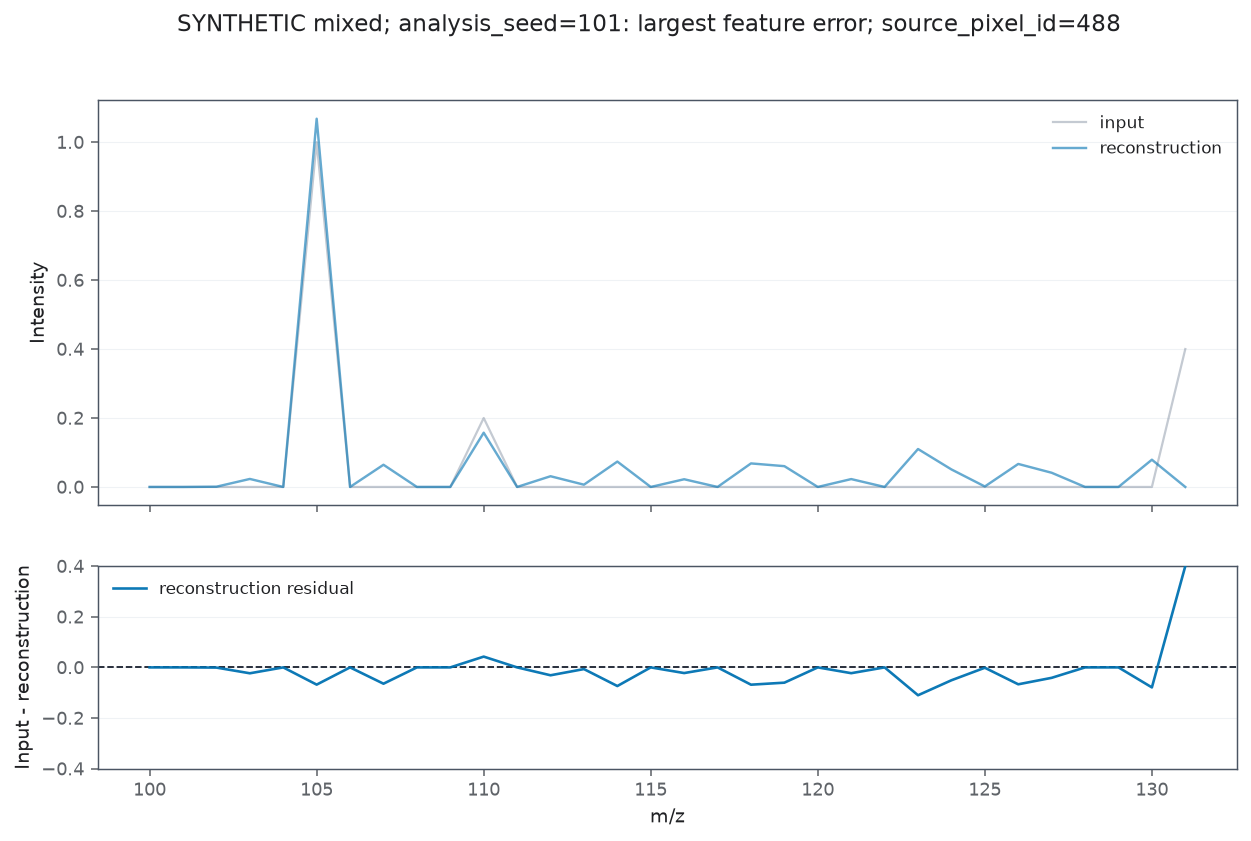

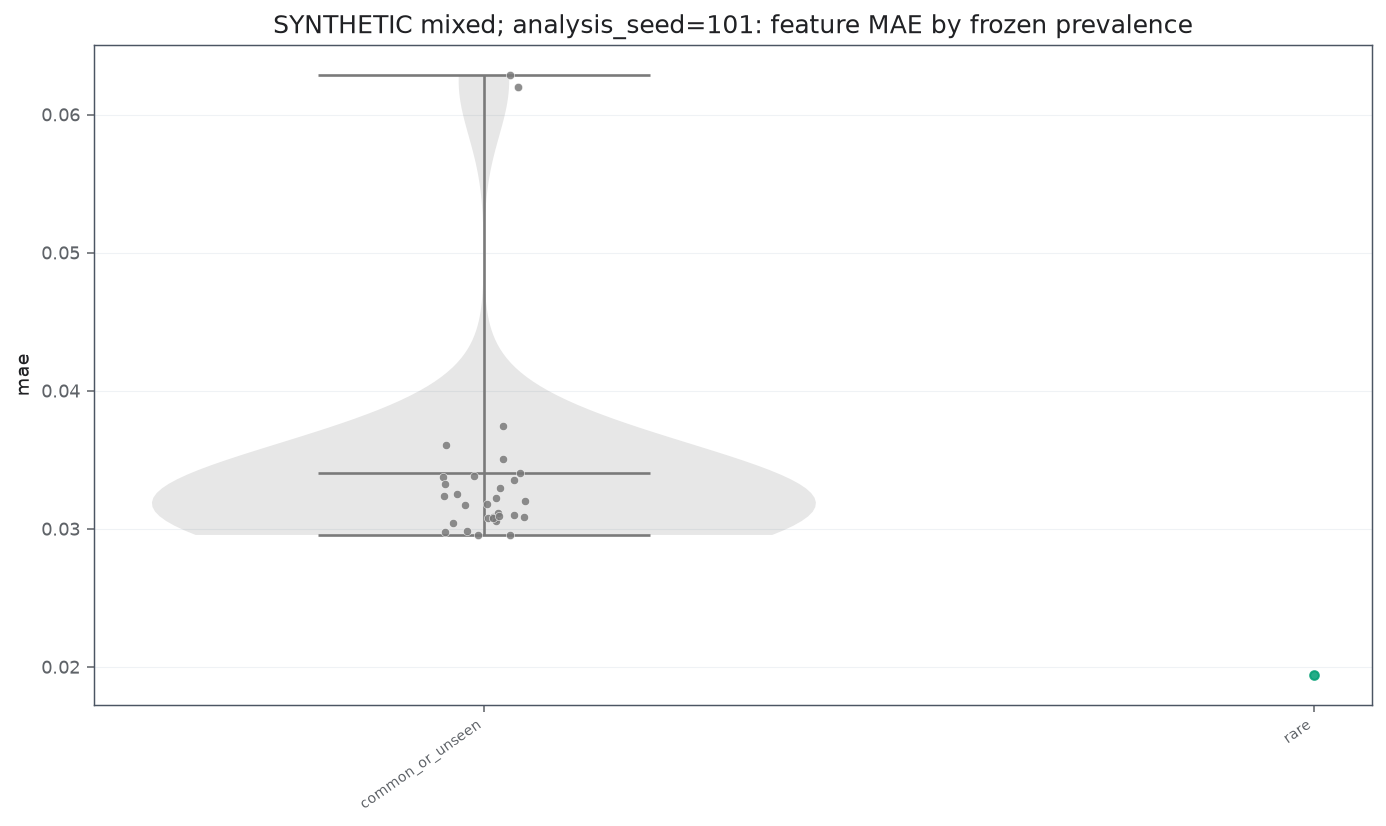

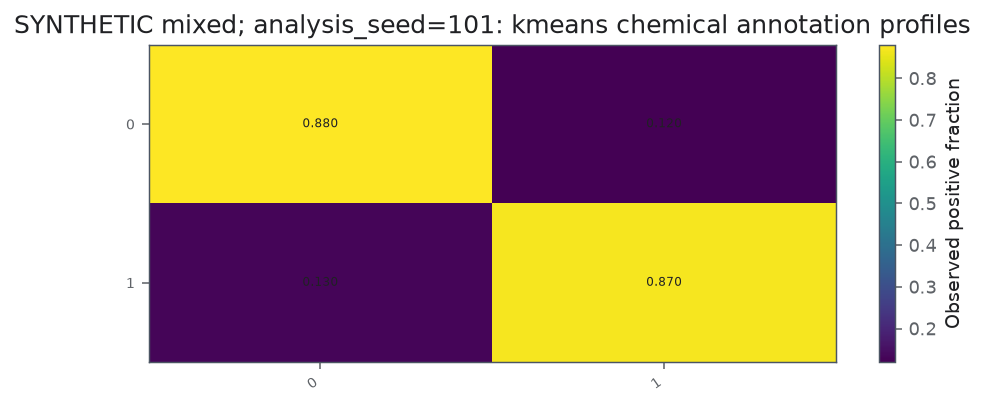

In [7]:
FIXTURE = "mixed"
SEED = settings["seeds"][0]
case = results / "cases" / f"{FIXTURE}_seed_{SEED}"
import pandas as pd
import json
display(json.loads((case / "numerical_values" / "summary.json").read_text())["prediction"])
display(pd.read_csv(case / "numerical_values" / "reconstruction_summary.csv"))
display(pd.read_csv(case / "numerical_values" / "reconstruction_worst_errors.csv").head(10))
display(Image(filename=str(case / "plots" / "worst_reconstruction.png")))
display(Image(filename=str(case / "plots" / "rare_feature_errors.png")))
display(Image(filename=str(case / "plots" / "chemical_profiles_kmeans.png")))

## Numerical precision and latent collapse

### Methodology

#### Theoretical

Effective covariance rank is exp(-sum Q log Q); participation ratio is 1/sum Q². Constant representations return zero. Finite and nonzero gradients are checked independently of rank.

#### Implementation

The diagnostics use scaled float64 SVD to avoid overflow while preserving eigenvalue ratios. Tests verify constant/rank-one cases and rotation/scale invariance. Existing Masserstein values are compared with scipy float64 Wasserstein; float64 autograd gradcheck validates derivatives away from nondifferentiable zero imbalance. Existing InfoNCE loss/gradients are compared between CPU and actual CUDA at T=0.07. Float32 tolerances are atol=1e-5 and rtol=1e-4, fixed before validation.

#### Figure descriptions

Numerical-check and gradient tables list actual devices, maximum absolute errors and finite gradient norms. They validate the reused calculations, not a trained encoder's gradient health. The eigenvalue table belongs to the selected synthetic latent.

### Remarks

Actual model gradient diagnostics require explicit named snapshots from the inference/verification adapter. A stable constant cluster remains a failed negative control.

### Notes

In [8]:
display(load_table(settings, "numerical_checks.csv"))
display(load_table(settings, "gradient_checks.csv"))
display(pd.read_csv(case / "numerical_values" / "latent_spectrum.csv"))
print("Canonical Markdown report:", results / "reports" / "validation_report.md")

,check,device,max_absolute_error,atol,rtol,passed
0,masserstein_independent_oracle,cpu,1.819594e-06,0.00001,0.0001,True
1,masserstein_independent_oracle,cuda,9.996427e-07,0.00001,0.0001,True
2,masserstein_float64_gradcheck,cpu,NaN,0.00001,0.0010,True
3,infonce_cpu_device_loss_and_gradient,cpu,0.000000e+00,0.00001,0.0001,True
4,infonce_cpu_device_loss_and_gradient,cuda,7.450581e-08,0.00001,0.0001,True


,name,present,finite,elements,norm,zero_fraction
0,masserstein_cpu,True,True,256,6.436452,0.0
1,masserstein_cuda,True,True,256,6.436453,0.0
2,infonce_cpu,True,True,160,1.356354,0.0
3,infonce_cuda,True,True,160,1.356354,0.0


,component,scaled_eigenvalue,variance_fraction
0,0,0.086001,0.404031
1,1,0.046476,0.218343
2,2,0.041264,0.193857
3,3,0.039117,0.183769


Canonical Markdown report: /home/max/repositories/MSIAutoEncoderWrapper/assets/experiments/autoencoder_architecture/notebooks/agent_analysis_validation/part_0_analysis_validation_results/reports/validation_report.md


## Results / Summary

### LLM

Current spectral results compare the same inputs across raw spectra and six preserved trained checkpoints, using CUDA K-means, diagonal GMM and DBSCAN. The displayed references include two stripes, five stripes and five concentric regions, at two noise levels. Inspect per-region scores, noise coverage and convergence together with the image panels. Historical model families do not provide a controlled pretraining ablation. Biological segmentation still requires a compatible input representation and accepted H&E→MSI registration.

### Person
